In [1]:
# Bibliotecas e funções
import os
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from PIL import Image
from skimage.measure import label
from scipy.spatial import cKDTree
from skimage.morphology import remove_small_objects
from skimage.color import label2rgb, gray2rgb
from skimage.measure import label, regionprops
from skimage.morphology import skeletonize
from skimage.util import invert, img_as_float
from skan import Skeleton, summarize
from itertools import combinations
from scipy.ndimage import distance_transform_edt
from skimage.segmentation import watershed
from skimage.io import imread
from skimage import filters, restoration
from tqdm import tqdm
from IPython.display import clear_output

## Ideias iniciais - Comparações

In [2]:
def podar_esqueleto_por_orientacao(esqueleto_img, angulo_limite_graus=45, analise_local=True, range_local = 20):
    """
    Poda ramos em junções de um esqueleto. A lógica é preservar o par de
    ramos mais colinear (mais próximo de 180°) e remover os demais.

    Args:
        esqueleto_img (np.ndarray): A imagem binária do esqueleto.
        angulo_limite_graus (int): O desvio máximo em graus em relação a uma
                                   linha reta (180°) para considerar dois
                                   ramos como uma continuação. Se a melhor
                                   combinação de ramos tiver uma diferença
                                   maior que este limite, nada é podado.

    Returns:
        np.ndarray: A imagem do esqueleto podado.
    """
    # 1. Analisar o esqueleto usando a biblioteca 'skan'
    esqueleto_obj = Skeleton(esqueleto_img)
    summary = summarize(esqueleto_obj, separator='-')

    # Se skan não encontrar ramos, retorna a imagem original
    if summary.shape[0] == 0:
        # print("Nenhum ramo encontrado no esqueleto.")
        return np.copy(esqueleto_img)

    esqueleto_podado = np.copy(esqueleto_img)
    
    # 2. Encontrar pontos de junção (nós com grau >= 3)
    pontos_de_juncao_ids = np.where(esqueleto_obj.degrees >= 3)[0]

    # print(f"Encontrados {len(pontos_de_juncao_ids)} pontos de junção para análise.")

    # 3. Analisar cada junção
    for junction_id in pontos_de_juncao_ids:
        # Pega as coordenadas da junção atual
        j_coords = esqueleto_obj.coordinates[junction_id]
        
        # Encontra todos os ramos (arestas) que se conectam a esta junção
        ramos_conectados = summary[(summary['node-id-src'] == junction_id) | (summary['node-id-dst'] == junction_id)]
        
        # Pula se, por algum motivo, não for uma junção válida (menos de 3 ramos)
        if len(ramos_conectados) < 3:
            continue
        
        # Calcula o ângulo de cada ramo que sai da junção
        ramos_info = []
        for _, ramo in ramos_conectados.iterrows():
            # Precisamos do ID do outro nó para formar o vetor do ramo

            if analise_local:
                ramo_pixels = esqueleto_obj.path_coordinates(int(ramo.name))
                tam_ramo = len(ramo_pixels)

                # if tam_ramo < 5:
                #     print(f"  -> Ramo {ramo.name} é muito curto para análise local. Ignorando.")
                #     continue
                if ramo['node-id-src'] == junction_id:
                    if tam_ramo > range_local:
                        other_coords = ramo_pixels[range_local]
                    else:
                        other_node_id = ramo['node-id-dst']
                        other_coords = esqueleto_obj.coordinates[int(other_node_id)]
                    junc_is_src = 1
                else:
                    if tam_ramo > range_local:
                        other_coords = ramo_pixels[-(range_local-1)]
                    else:
                        other_node_id = ramo['node-id-src']
                        other_coords = esqueleto_obj.coordinates[int(other_node_id)]
                    junc_is_src = 0
            else:
                other_node_id = ramo['node-id-dst'] if ramo['node-id-src'] == junction_id else ramo['node-id-src']
                junc_is_src = 1 if ramo['node-id-src'] == junction_id else 0
                other_coords = esqueleto_obj.coordinates[int(other_node_id)]

            # Calcula o vetor (dy, dx) do centro da junção para a ponta do ramo
            dy = other_coords[0] - j_coords[0]
            dx = other_coords[1] - j_coords[1]
            
            # Calcula o ângulo e o ID do ramo (skeleton-id)
            angle = np.degrees(np.arctan2(-dy, dx)) # -dy para alinhar com o sistema de coordenadas de imagem
            ramos_info.append({'id': ramo.name, 'angle': angle, 'junc_is_src': junc_is_src})

        # 4. Encontrar o par de ramos mais colinear
        melhor_par = None
        menor_diff_de_180 = 180.0

        # Testa todas as combinações de 2 ramos
        for r1, r2 in combinations(ramos_info, 2):
            # Calcula a diferença absoluta de ângulo
            diff = abs(r1['angle'] - r2['angle'])
            
            # Queremos a diferença em relação a 180 graus
            diff_de_180 = abs(diff - 180)
            
            # Corrige o caso em que o ângulo passa de 360 (e.g., -170 e 170)
            if diff_de_180 > 180:
                diff_de_180 = 360 - diff_de_180

            # Se esta for a combinação mais próxima de 180° até agora, salva
            if diff_de_180 < menor_diff_de_180:
                menor_diff_de_180 = diff_de_180
                # Armazena os IDs dos ramos do melhor par
                melhor_par = {r1['id'], r2['id']}

        # 5. Aplicar a poda se um par adequado for encontrado
        # O par deve ser colinear o suficiente (abaixo do nosso 'angulo_limite_graus')
        if melhor_par and menor_diff_de_180 < angulo_limite_graus:
            # Itera por todos os ramos da junção novamente
            for ramo in ramos_info:
                if ramo['id'] not in melhor_par:
                    # print(f"  -> Podando ramo {ramo['id']} (desalinhado) na junção {junction_id}.")
                    # Obtém as coordenadas de todos os pixels do ramo a ser podado
                    path_coords = esqueleto_obj.path_coordinates(int(ramo['id']))
                    # Define o valor desses pixels para 0, removendo-os da imagem
                    if len(path_coords) > 1:
                        if ramo['junc_is_src'] == 1:
                            # Se o ramo é a origem, remove o primeiro pixel
                            esqueleto_podado[path_coords[1, 0], path_coords[1, 1]] = 0
                        else:
                            # Se o ramo é o destino, remove o último pixel
                            esqueleto_podado[path_coords[-2, 0], path_coords[-2, 1]] = 0
        else:
            for ramo in ramos_info:
                # print(f"  -> Podando todos os ramos na junção {junction_id} (nenhum par colinear encontrado).")
                # Obtém as coordenadas de todos os pixels do ramo a ser podado
                path_coords = esqueleto_obj.path_coordinates(int(ramo['id']))
                # Define o valor desses pixels para 0, removendo-os da imagem
                if len(path_coords) > 1:
                    if ramo['junc_is_src'] == 1:
                        # Se o ramo é a origem, remove o primeiro pixel
                        esqueleto_podado[path_coords[1, 0], path_coords[1, 1]] = 0
                    else:
                        # Se o ramo é o destino, remove o último pixel
                        esqueleto_podado[path_coords[-2, 0], path_coords[-2, 1]] = 0

    return esqueleto_podado

def label_binary_img(binary_img, connectivity=2, remove_small_obj=False, min_size=100):
    """
    Rotula uma imagem binária, atribuindo rótulos únicos a componentes conectados.

    Args:
        binary_img (np.ndarray): Imagem binária (True/False ou 1/0).
        connectivity (int): Conectividade a ser usada (1 ou 2).

    Returns:
        np.ndarray: Imagem rotulada onde cada componente conectado tem um rótulo único.
    """
    
    esqueleto_img = skeletonize(binary_img)

    skeleton_obj = Skeleton(esqueleto_img)

    degrees = skeleton_obj.degrees
    indices_juncoes = np.where(degrees >= 3)[0]

    coords_juncoes = skeleton_obj.coordinates[indices_juncoes].astype(int)
    esqueleto_colorido = gray2rgb((esqueleto_img * 255).astype(np.uint8))
    esqueleto_podado = np.copy(esqueleto_img)

    # print(f"Encontrados {len(coords_juncoes)} pontos de junção. Colorindo de vermelho e removendo...")

    offset = 0

    for y, x in coords_juncoes:
        y_min = max(0, y - offset)
        y_max = min(esqueleto_colorido.shape[0], y + offset + 1)
        x_min = max(0, x - offset)
        x_max = min(esqueleto_colorido.shape[1], x + offset + 1)
        esqueleto_colorido[y_min:y_max, x_min:x_max] = (255, 0, 0)

        # Remove todos os pixels conectados ao ponto de junção
        esqueleto_podado[y, x+1] = False
        esqueleto_podado[y, x-1] = False
    
    esqueleto_rotulado = label(esqueleto_podado, connectivity=connectivity).astype(np.uint16)

    if remove_small_obj:
        esqueleto_rotulado = remove_small_objects(esqueleto_rotulado, min_size=min_size)

    coords_esqueleto = np.argwhere(esqueleto_rotulado > 0)
    labels_esqueleto = esqueleto_rotulado[coords_esqueleto[:, 0], coords_esqueleto[:, 1]]
    coords_forma = np.argwhere(binary_img)

    kdtree = cKDTree(coords_esqueleto)
    _, indices_vizinhos = kdtree.query(coords_forma)

    labels_mapeados = labels_esqueleto[indices_vizinhos]

    binary_rotulada = np.zeros_like(binary_img, dtype=np.uint8)
    binary_rotulada[coords_forma[:, 0], coords_forma[:, 1]] = labels_mapeados

    return esqueleto_colorido, esqueleto_rotulado, esqueleto_podado, binary_rotulada, coords_juncoes

def separar_fibras(binary_img, angulo_limite_poda=45, remover_pequenos_esqueletos=True, tam_min_esqueleto=100, analise_local=True, range_local = 20):
    """
    Pipeline completo para esqueletizar, podar junções e rotular fibras.

    Args:
        binary_img (np.ndarray): Imagem binária original das fibras.
        angulo_limite_poda (int): Desvio máximo de 180° para considerar um par de ramos como contínuo.
        remover_pequenos_esqueletos (bool): Se True, remove pequenos fragmentos de esqueleto após a poda.
        tam_min_esqueleto (int): Tamanho mínimo do esqueleto para ser mantido.

    Returns:
        np.ndarray: Imagem final com cada fibra separada e rotulada.
        np.ndarray: Imagem dos esqueletos rotulados e podados.
    """
    # print("1. Esqueletizando a imagem binária...")
    esqueleto_img = skeletonize(binary_img)

    # print("2. Podando junções com base na colinearidade dos ramos...")
    esqueleto_podado = podar_esqueleto_por_orientacao(esqueleto_img, angulo_limite_graus=angulo_limite_poda, analise_local=analise_local, range_local=range_local)

    # print("3. Rotulando os segmentos de esqueleto desconectados...")
    esqueleto_rotulado = label(esqueleto_podado, connectivity=2) # connectivity=2 é geralmente melhor

    if remover_pequenos_esqueletos:
        # print(f"4. Removendo fragmentos de esqueleto menores que {tam_min_esqueleto} pixels...")
        esqueleto_rotulado = remove_small_objects(esqueleto_rotulado, min_size=tam_min_esqueleto)

    # (A próxima etapa responde à sua Questão 2)
    # print("5. Propagando rótulos dos esqueletos para as fibras usando Watershed...")
    
    # Calcula o mapa de distância da imagem binária original
    # A distância será maior no centro das fibras
    distancia = distance_transform_edt(binary_img)

    # O algoritmo watershed "inunda" a imagem a partir de marcadores.
    # Nossos marcadores são os esqueletos rotulados.
    # A topografia é o negativo da distância (inundamos dos picos para os vales).
    # A máscara garante que os rótulos fiquem contidos apenas dentro das fibras originais.
    fibras_rotuladas = watershed(-distancia, markers=esqueleto_rotulado, mask=binary_img)
    
    return fibras_rotuladas, esqueleto_rotulado

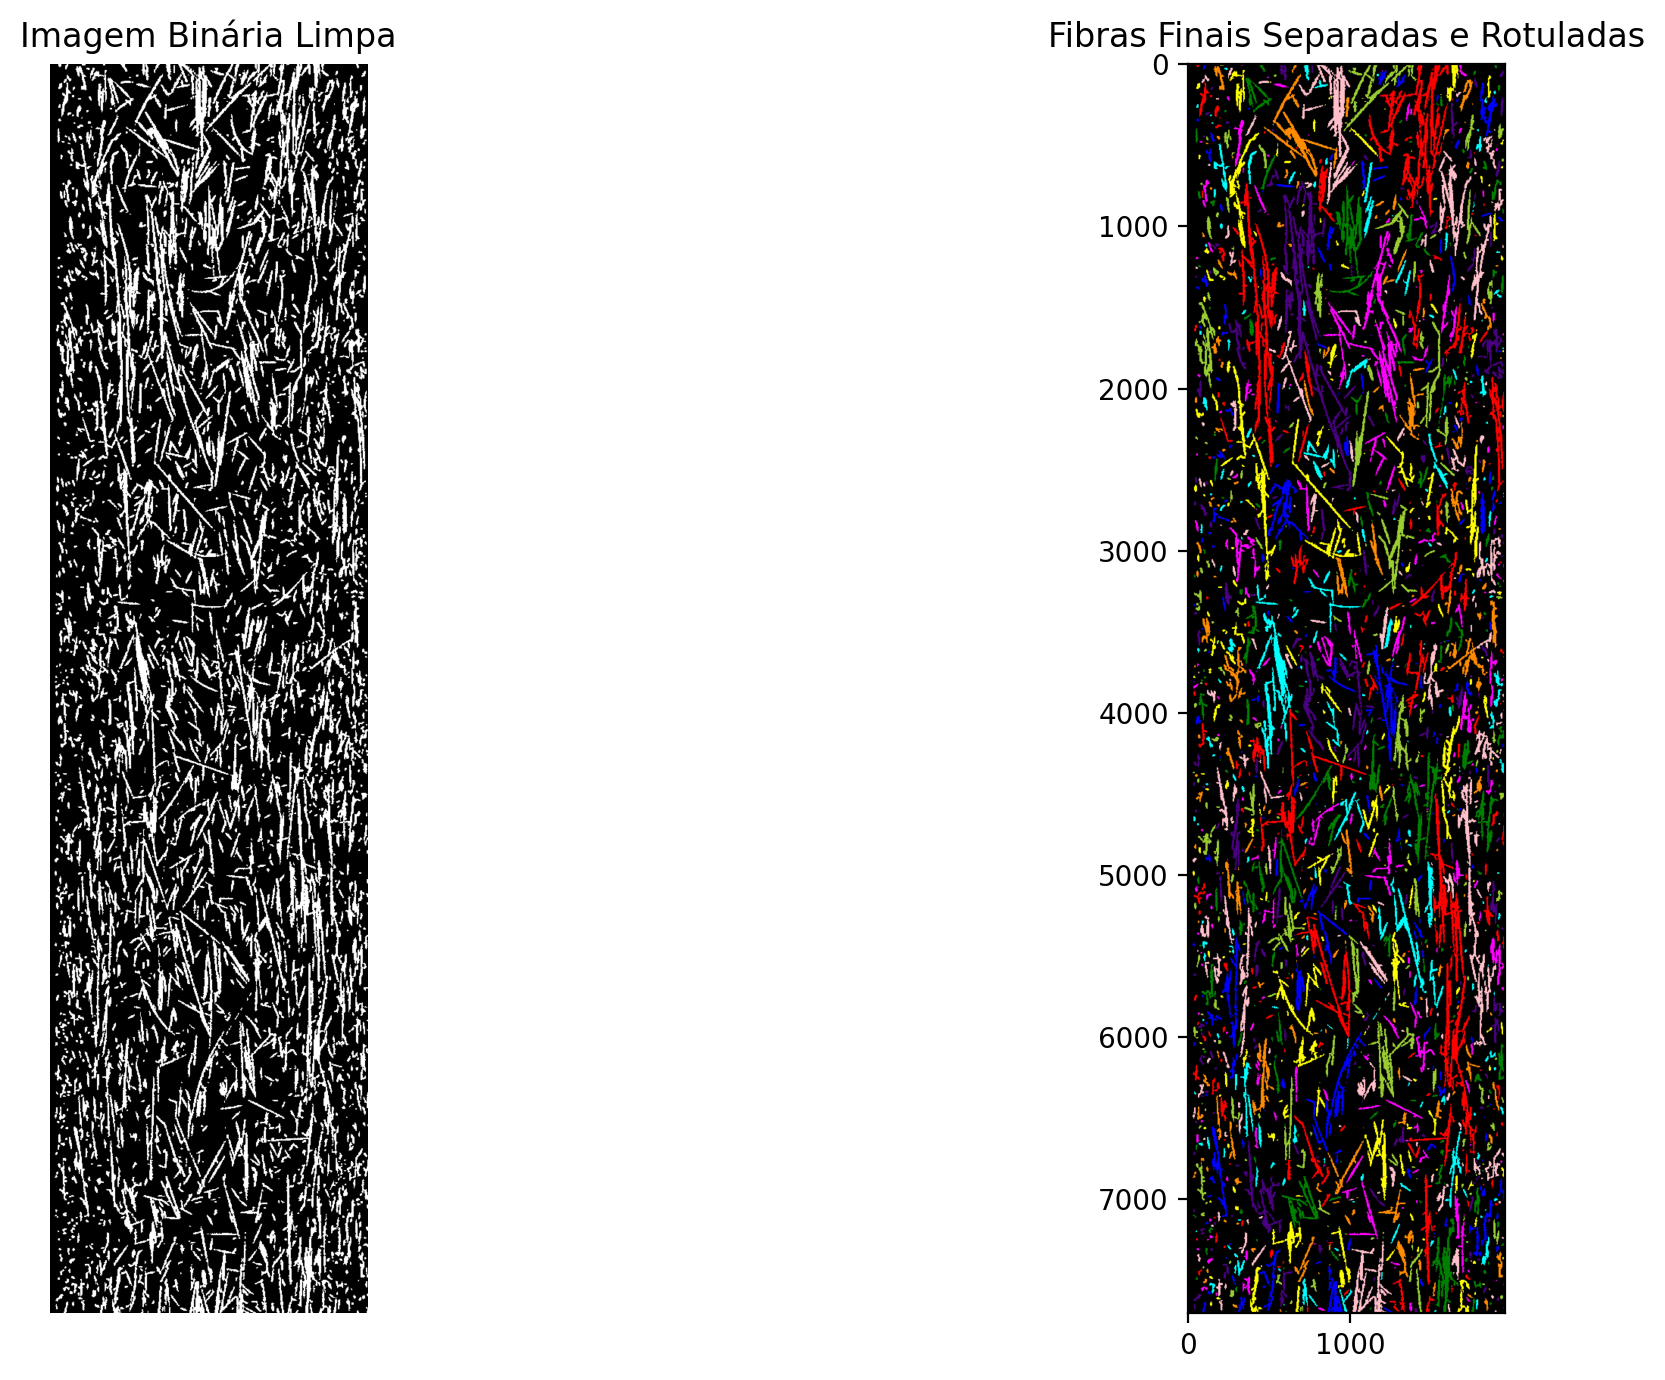

In [3]:
img = Image.open("../data/slice_050.tiff").convert("L")
imagem = np.array(img)
binaria = imagem > 200
binaria_limpa = remove_small_objects(binaria, min_size=50)

rotulada = label(binaria_limpa, connectivity=2)

plt.figure(figsize=(15, 7), dpi=200)

plt.subplot(1, 2, 1)
plt.imshow(binaria_limpa, cmap='gray')
plt.title("Imagem Binária Limpa")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(label2rgb(rotulada, bg_label=0), cmap='gray')
plt.title("Fibras Finais Separadas e Rotuladas")
# plt.axis('off')

plt.tight_layout()
os.makedirs("img_res", exist_ok=True)
plt.savefig("./img_res/fred.png", dpi=500)
plt.show()

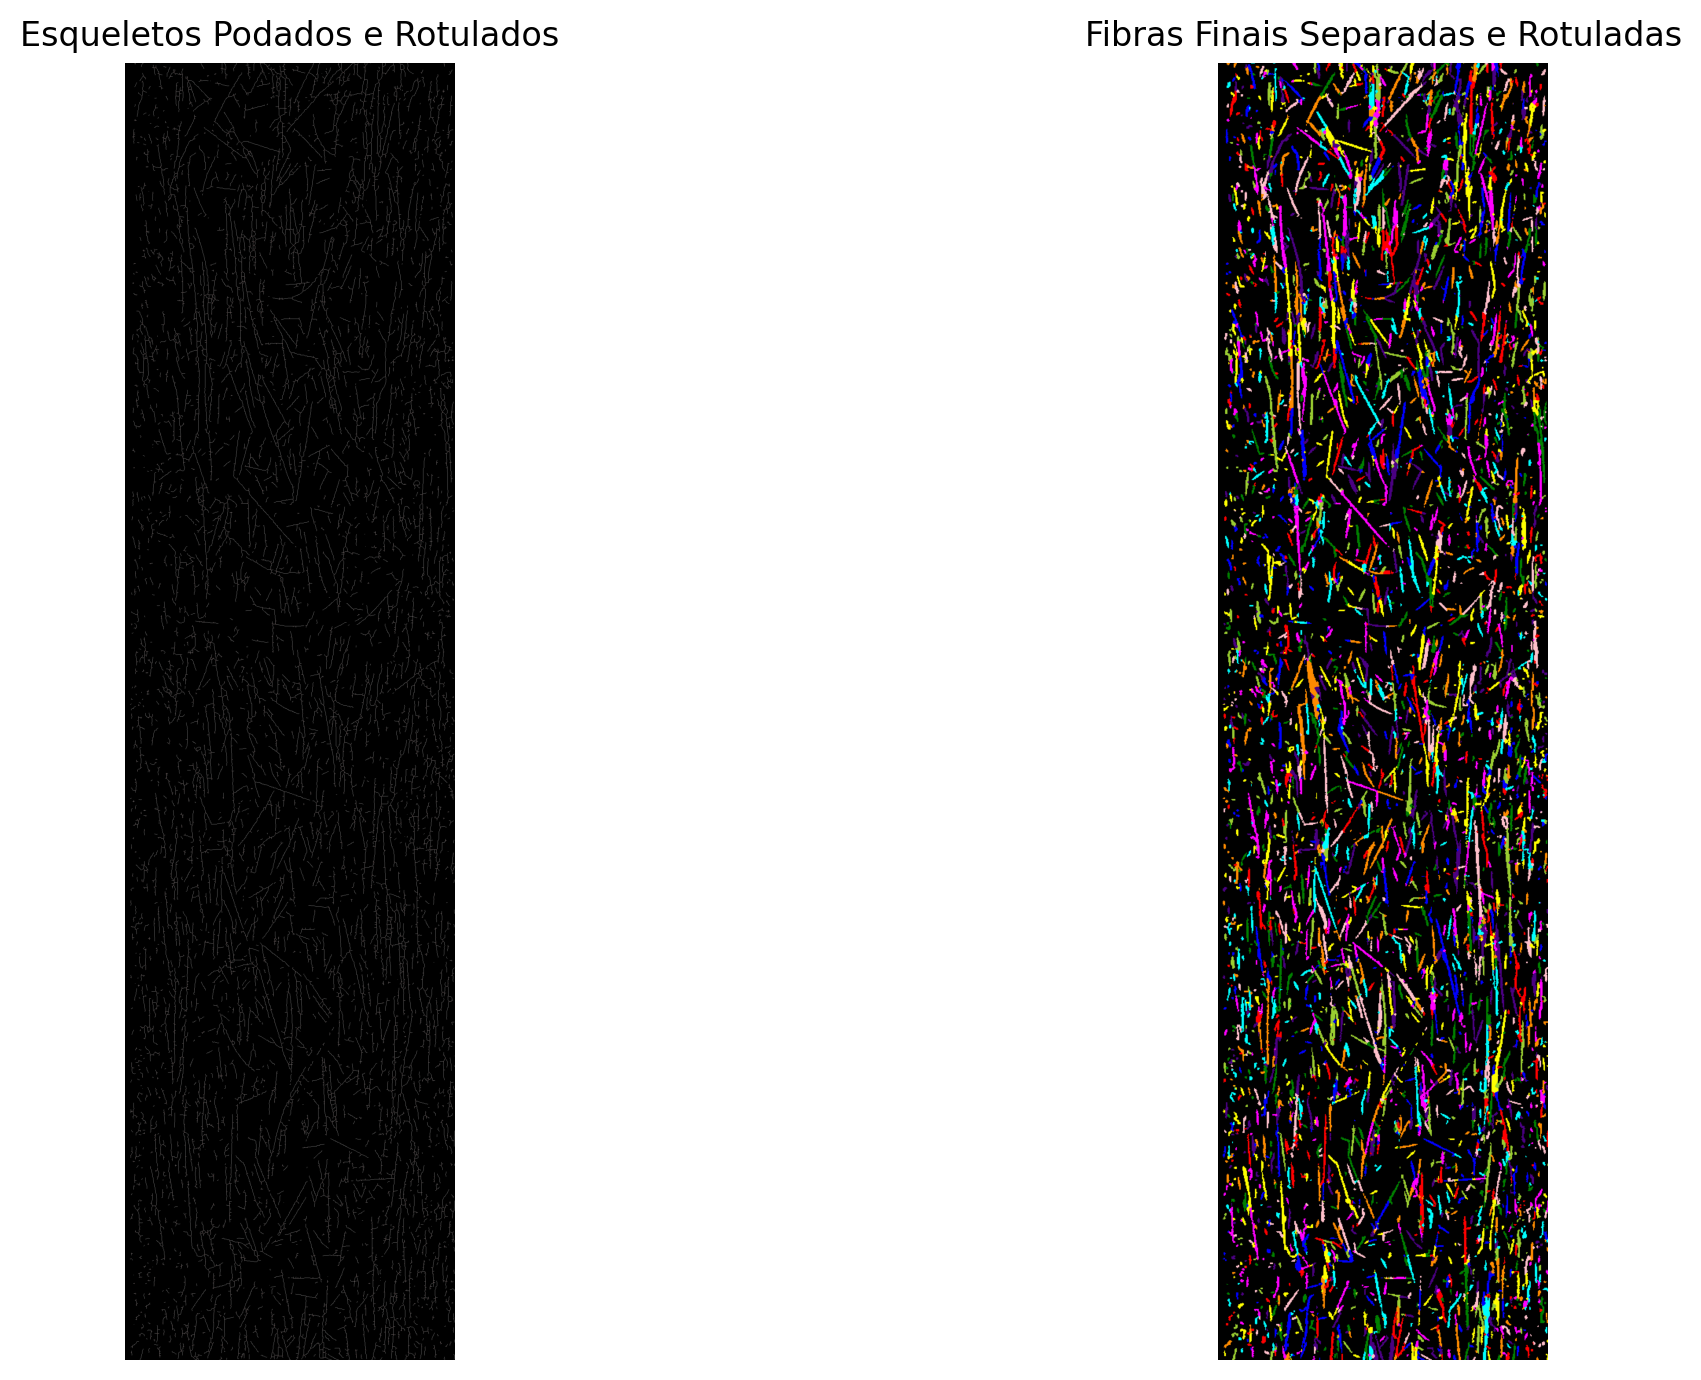

In [4]:
esqueleto_colorido, esqueleto_rotulado, esqueleto_sem_juncoes, binary_rotulada, coords_juncoes = label_binary_img(
    binaria_limpa, connectivity=2, remove_small_obj=True, min_size=10)

# Visualização dos resultados
plt.figure(figsize=(15, 7), dpi=200)

plt.subplot(1, 2, 1)
# plt.imshow(label2rgb(esqueleto_rotulado, bg_label=0), cmap='gray')
plt.imshow(esqueleto_colorido)
plt.title("Esqueletos Podados e Rotulados")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(label2rgb(binary_rotulada, bg_label=0), cmap='gray')
plt.title("Fibras Finais Separadas e Rotuladas")
plt.axis('off')

plt.tight_layout()
plt.savefig("./img_res/poda_arb.png", dpi=500)
plt.show()

In [15]:
coords_juncoes.shape[0] / (esqueleto_sem_juncoes.sum()+coords_juncoes.shape[0])

# coords_juncoes.shape

np.float64(0.019825185237085954)

In [ ]:
analise_local = True
fibras_separadas, esqueletos_separados = separar_fibras(
    binaria_limpa, 
    angulo_limite_poda=45,
    remover_pequenos_esqueletos=True, 
    tam_min_esqueleto=20,
    analise_local=analise_local,
    range_local=30
)

# Visualização dos resultados
plt.figure(figsize=(15, 7), dpi=200)

plt.subplot(1, 2, 1)
# plt.imshow(label2rgb(esqueletos_separados, bg_label=0), cmap='gray')
plt.imshow(esqueleto_colorido, cmap='gray')
plt.title("Esqueletos Podados e Rotulados")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(label2rgb(fibras_separadas, bg_label=0), cmap='gray')
plt.title("Fibras Finais Separadas e Rotuladas")
# plt.axis('off')

plt.tight_layout()
if analise_local:
    plt.savefig("./img_res/poda_orient_local.png", dpi=500)
else:
    plt.savefig("./img_res/poda_orient.png", dpi=500)
plt.show()

In [ ]:
# 986, 1234, 3546
idx_junc = 367

esqueleto = skeletonize(binaria_limpa)

print(esqueleto.shape)

print(coords_juncoes[idx_junc])

coords = coords_juncoes[idx_junc]

offset_vert = 50
offset_horiz = 50

# [7090, 1130], [6730, 870], [6700, 620]

coords = [4600, 1000]

offset_vert = 200
offset_horiz = 100

xmin = max(0, coords[1] - offset_horiz)
xmax = min(esqueleto.shape[1], coords[1] + offset_horiz)
ymin = max(0, coords[0] - offset_vert)
ymax = min(esqueleto.shape[0], coords[0] + offset_vert)

plt.figure(figsize=(16, 8), dpi=100)
plt.imshow(binaria_limpa[ymin:ymax, xmin:xmax], cmap='gray')
plt.show()


In [ ]:
esqueleto_colorido, esqueleto_rotulado, esqueleto_sem_juncoes, binary_rotulada, _ = label_binary_img(binaria_limpa[ymin:ymax, xmin:xmax], connectivity=2, remove_small_obj=True, min_size=20)

fibras_separadas, esqueletos_separados = separar_fibras(binaria_limpa[ymin:ymax, xmin:xmax], angulo_limite_poda=45, remover_pequenos_esqueletos=True, tam_min_esqueleto=20, analise_local=True, range_local = 30)

# plt.figure(figsize=(16, 8), dpi=100)
# plt.imshow(esqueleto_colorido, cmap='gray')
# plt.imshow(label2rgb(esqueletos_separados, bg_label=0), cmap='gray')
# plt.imshow(label2rgb(fibras_separadas, bg_label=0), cmap='gray')
# plt.show()

In [ ]:
plt.figure(figsize=(16, 8), dpi=200)
plt.subplot(1, 4, 1)
plt.imshow(binaria_limpa[ymin:ymax, xmin:xmax], cmap='gray')

plt.subplot(1, 4, 2)
plt.imshow(esqueleto_colorido, cmap='gray')

plt.subplot(1, 4, 3)
plt.imshow(label2rgb(esqueletos_separados, bg_label=0), cmap='gray')

plt.subplot(1, 4, 4)
plt.imshow(label2rgb(fibras_separadas, bg_label=0), cmap='gray')

plt.tight_layout()
plt.show()

## Composição 3D

Para usar o terminal X11:
- Usar powershell;
- setar $env:DISPLAY = "localhost:0";

In [ ]:
# Carregando a imagem TIFF do bloco inteiro
tiff_img = tifffile.imread("./data/data/PPGF40HNT0-1.0.tif")

# Convertendo a imagem para escala de cinza de 8 bits
tiff_img = (tiff_img / np.max(tiff_img) * 255).astype(np.uint8)

In [4]:
tiff_img.shape

(1649, 1055, 658)

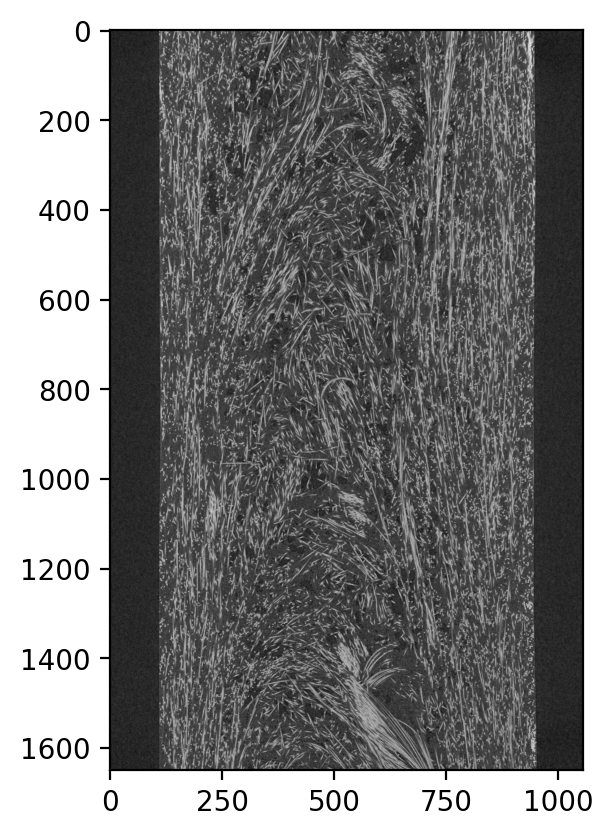

In [5]:
plt.figure(dpi=200)
plt.imshow(tiff_img[:,:, 300], cmap='gray')
plt.show()

In [6]:
# Selecionando uma seção 3D do bloco inteiro
array_img = np.array(tiff_img)
cropped_img = array_img[600:900, 300:600, 200:500]

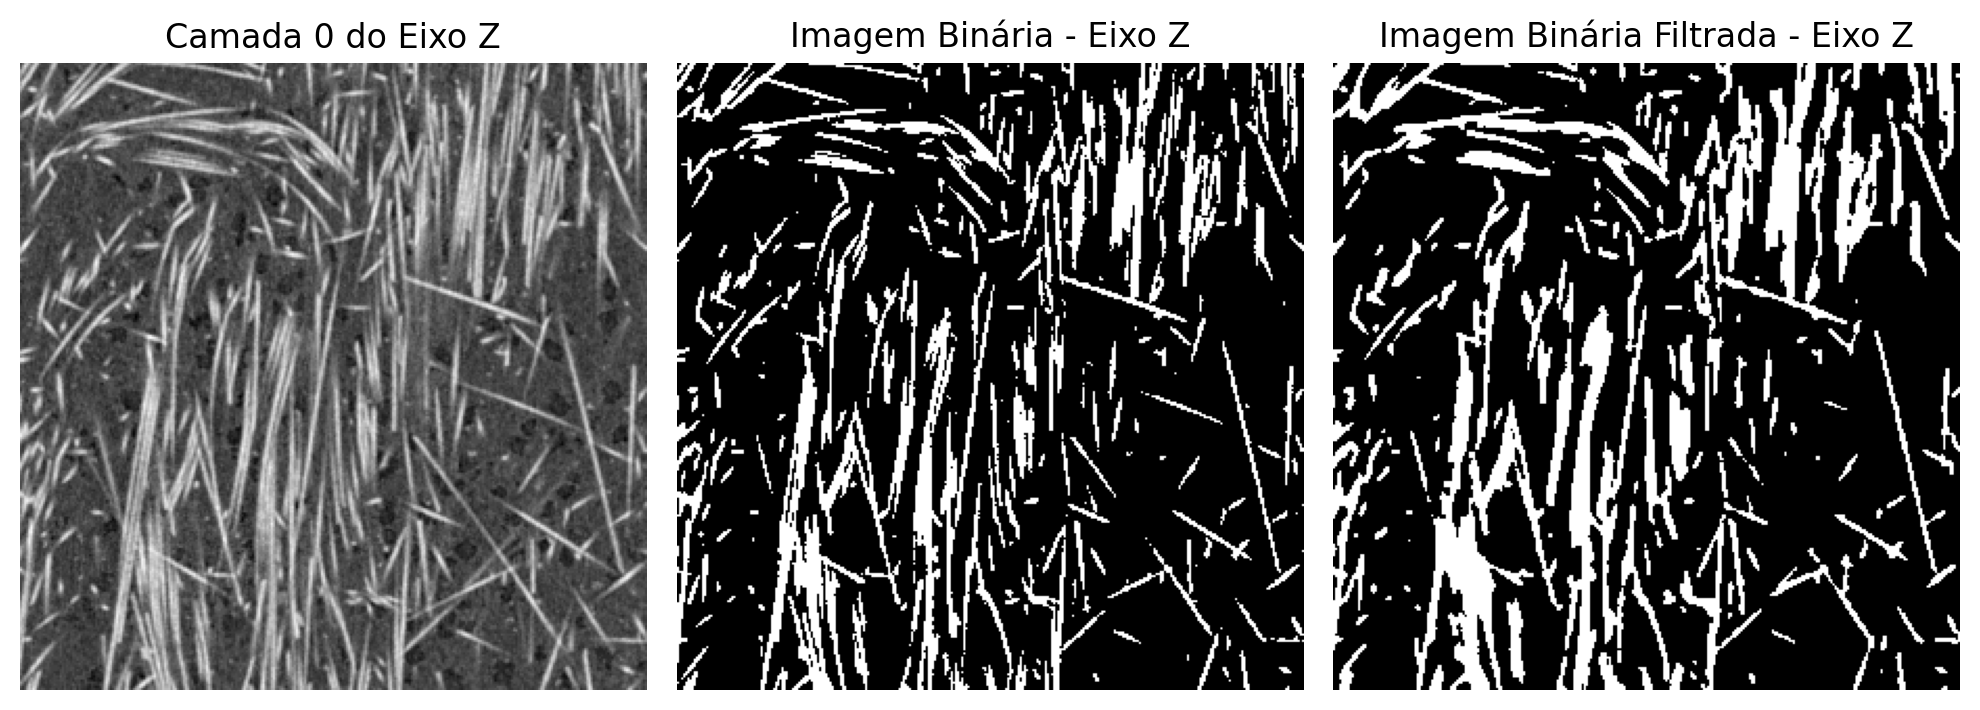

In [ ]:
# Binarizando e testando filtros
binary_cropped = cropped_img > 113

filtered_img = np.empty_like(cropped_img)

filtered_img = filters.median(cropped_img) # filtro de mediana

binary_filtered = filtered_img > 110
# binary_filtered = remove_small_objects(binary_filtered, min_size=1)

eixo = 'z'
layer = 0

if eixo == 'x':
    cropped = cropped_img[layer, :, :]
    binary_c = binary_cropped[layer, :, :]
    binary_f = binary_filtered[layer, :, :]
elif eixo == 'y':
    cropped = cropped_img[:, layer, :]
    binary_c = binary_cropped[:, layer, :]
    binary_f = binary_filtered[:, layer, :]
elif eixo == 'z':
    cropped = cropped_img[:, :, layer]
    binary_c = binary_cropped[:, :, layer]
    binary_f = binary_filtered[:, :, layer]

plt.figure(figsize=(10, 5), dpi=200)

plt.subplot(1, 3, 1)
plt.imshow(cropped, cmap='gray')
plt.title(f"Camada {layer} do Eixo {eixo.upper()}")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(binary_c, cmap='gray')
plt.title(f"Imagem Binária - Eixo {eixo.upper()}")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(binary_f, cmap='gray')
plt.title(f"Imagem Binária Filtrada - Eixo {eixo.upper()}")
plt.axis('off')

plt.tight_layout()
plt.show()

# salvando a imagem binária
# tifffile.imwrite("./data/2d-res/binary_cropped.tif", binary_cropped.astype(np.uint8) * 255)
# scp homero_castro@litc59:/home/homero_castro/toronto/data/2d-res/binary_cropped.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\data\2d-res
# napari ./data/2d-res/binary_cropped.tif

In [8]:
# Testando método de separação no bloco selecionado
fibras_separadas = np.zeros_like(cropped_img)
esqueletos_separados = np.zeros_like(cropped_img)

chosen_binary = binary_cropped

if eixo == 'x':
    for each_slice in tqdm(range(chosen_binary.shape[0]), desc="Processando slices ao longo do eixo X"):
        chosen_slice = chosen_binary[each_slice, :, :]
        # print(f"\nProcessando slice {each_slice+1}/{chosen_binary.shape[0]}...\n")
        fibras_separadas[each_slice, :, :], esqueletos_separados[each_slice, :, :] = separar_fibras(
            chosen_slice,
            angulo_limite_poda=45,
            remover_pequenos_esqueletos=False,
            tam_min_esqueleto=3,
            analise_local=True,
            range_local=20
        )
        # clear_output(wait=True)
elif eixo == 'y':
    for each_slice in tqdm(range(chosen_binary.shape[1]), desc="Processando slices ao longo do eixo Y"):
        chosen_slice = chosen_binary[:, each_slice, :]
        # print(f"\nProcessando slice {each_slice+1}/{chosen_binary.shape[1]}...\n")
        fibras_separadas[:, each_slice, :], esqueletos_separados[:, each_slice, :] = separar_fibras(
            chosen_slice,
            angulo_limite_poda=45,
            remover_pequenos_esqueletos=False,
            tam_min_esqueleto=3,
            analise_local=True,
            range_local=20
        )
        # clear_output(wait=True)
elif eixo == 'z':
    for each_slice in tqdm(range(chosen_binary.shape[2]), desc="Processando slices ao longo do eixo Z"):
        chosen_slice = chosen_binary[:, :, each_slice]
        # print(f"\nProcessando slice {each_slice+1}/{chosen_binary.shape[2]}...\n")
        fibras_separadas[:, :, each_slice], esqueletos_separados[:, :, each_slice] = separar_fibras(
            chosen_slice,
            angulo_limite_poda=45,
            remover_pequenos_esqueletos=False,
            tam_min_esqueleto=3,
            analise_local=True,
            range_local=20
        )
        # clear_output(wait=True)

Processando slices ao longo do eixo Z:   0%|          | 0/300 [00:00<?, ?it/s]/tmp/ipykernel_6783/4081098227.py:19: VisibleDeprecationWarning: separator in column name will change to _ in version 0.13; to silence this warning, use `separator='-'` to maintain current behavior and use `separator='_'` to switch to the new default behavior.
  summary = summarize(esqueleto_obj)
Processando slices ao longo do eixo Z:   0%|          | 1/300 [00:07<35:42,  7.16s/it]/tmp/ipykernel_6783/4081098227.py:19: VisibleDeprecationWarning: separator in column name will change to _ in version 0.13; to silence this warning, use `separator='-'` to maintain current behavior and use `separator='_'` to switch to the new default behavior.
  summary = summarize(esqueleto_obj)
Processando slices ao longo do eixo Z: 100%|██████████| 300/300 [01:38<00:00,  3.05it/s]


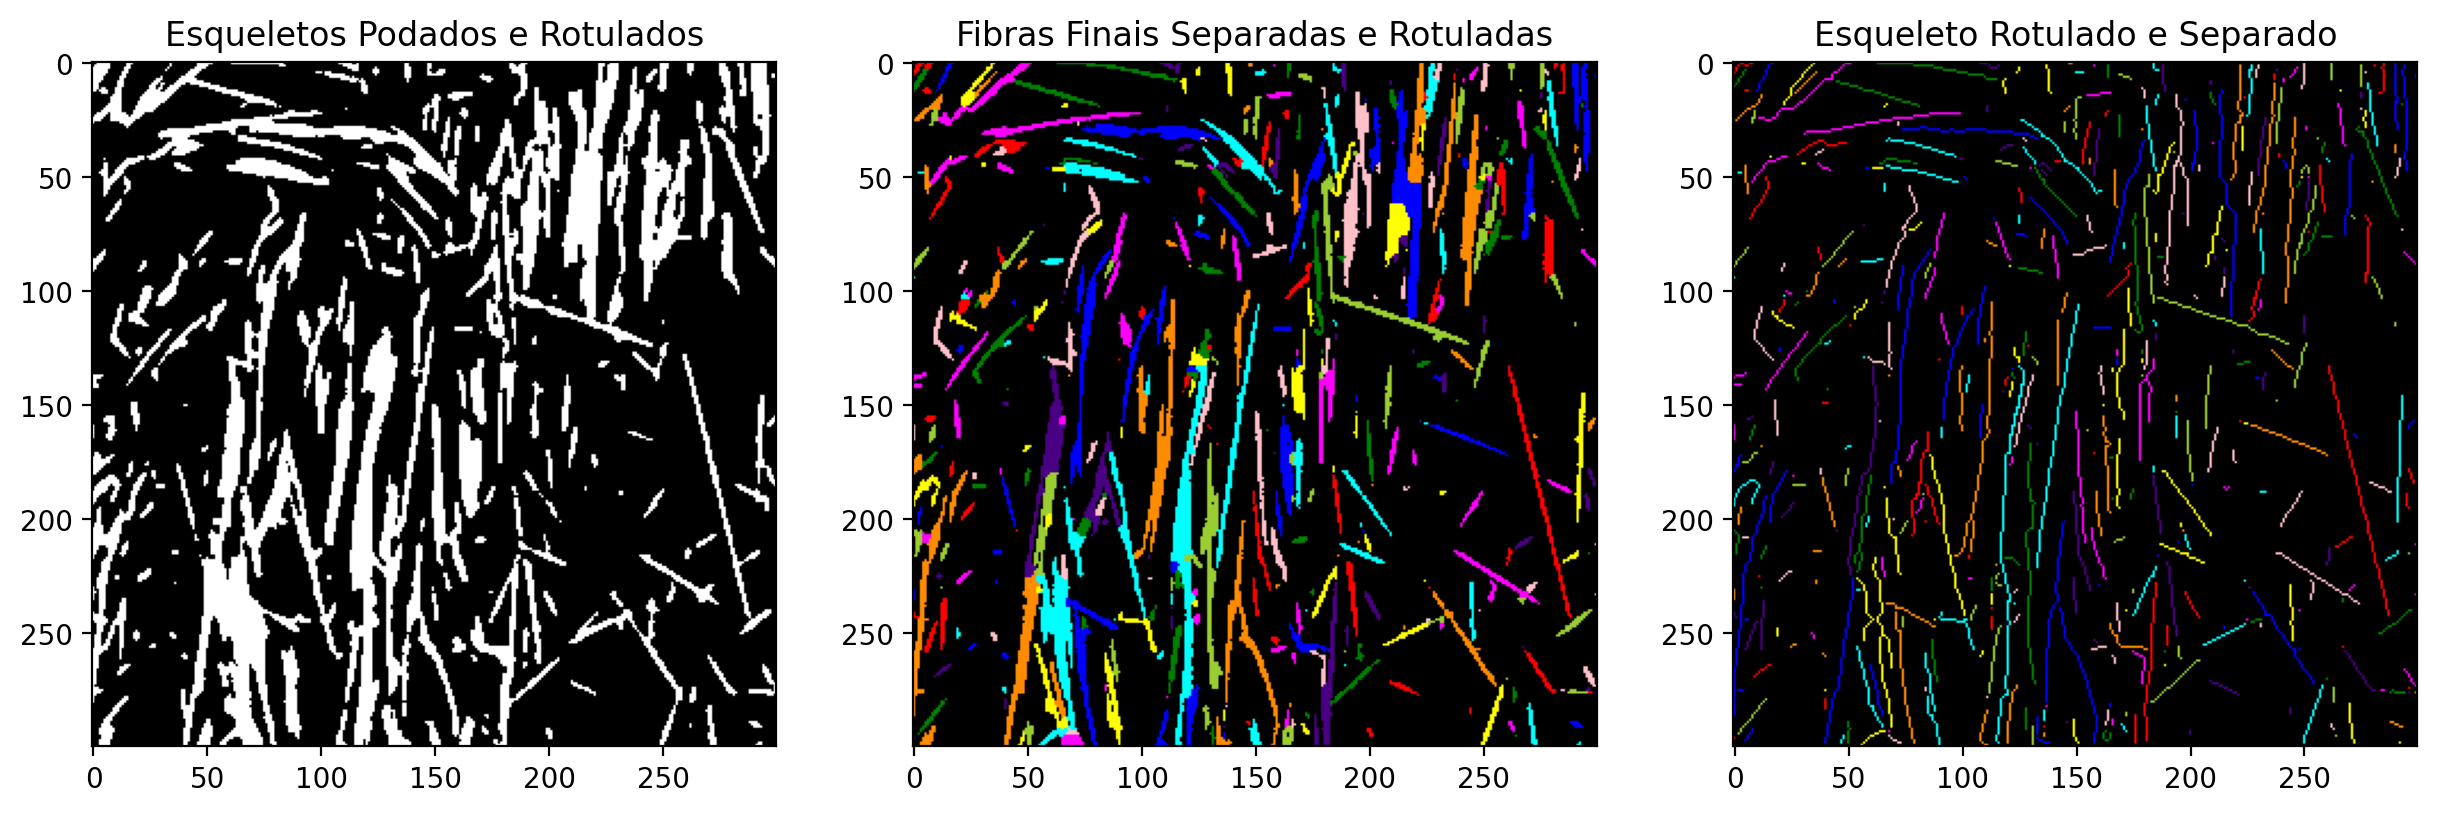

In [9]:
# Visualizando o resultado da segmentação
# layer = 100

if eixo == 'x':
    binary = binary_filtered[layer, :, :]
    fibras = fibras_separadas[layer, :, :]
    esqueletos = esqueletos_separados[layer, :, :]
elif eixo == 'y':
    binary = binary_filtered[:, layer, :]
    fibras = fibras_separadas[:, layer, :]
    esqueletos = esqueletos_separados[:, layer, :]
elif eixo == 'z':
    binary = binary_filtered[:, :, layer]
    fibras = fibras_separadas[:, :, layer]
    esqueletos = esqueletos_separados[:, :, layer]

# Visualização dos resultados
plt.figure(figsize=(15, 7), dpi=200)

plt.subplot(1, 3, 1)
# plt.imshow(label2rgb(esqueletos_separados, bg_label=0), cmap='gray')
plt.imshow(binary, cmap='gray')
plt.title("Esqueletos Podados e Rotulados")
# plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(label2rgb(fibras, bg_label=0), cmap='gray')
plt.title("Fibras Finais Separadas e Rotuladas")
# plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(label2rgb(label(esqueletos), bg_label=0), cmap='gray')
plt.title("Esqueleto Rotulado e Separado")
# plt.axis('off')

plt.show()

/tmp/ipykernel_6783/3580370814.py:5: VisibleDeprecationWarning: separator in column name will change to _ in version 0.13; to silence this warning, use `separator='-'` to maintain current behavior and use `separator='_'` to switch to the new default behavior.
  resumo = summarize(skeleton_obj)


,skeleton-id,node-id-src,node-id-dst,branch-distance,branch-type,mean-pixel-value,stdev-pixel-value,image-coord-src-0,image-coord-src-1,image-coord-dst-0,image-coord-dst-1,coord-src-0,coord-src-1,coord-dst-0,coord-dst-1,euclidean-distance
0,0,3,124,11.071068,0,1.0,0.0,0,8,4,0,0,8,4,0,8.944272
1,1,5,318,15.485281,0,2.0,0.0,0,17,12,10,0,17,12,10,13.892444
2,2,6,455,23.384776,0,3.0,0.0,0,35,18,22,0,35,18,22,22.203603
3,3,9,188,11.071068,1,4.0,0.0,0,51,6,43,0,51,6,43,10.000000
4,4,10,220,54.899495,0,5.0,0.0,0,63,7,115,0,63,7,115,52.469038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
500,475,6588,6611,1.000000,0,221.0,0.0,293,200,294,200,293,200,294,200,1.000000
501,476,6604,6627,1.000000,0,222.0,0.0,294,136,295,136,294,136,295,136,1.000000
502,477,6616,6683,3.414214,0,223.0,0.0,295,48,298,47,295,48,298,47,3.162278
503,478,6620,6687,6.242641,0,224.0,0.0,295,68,298,73,295,68,298,73,5.830952


,skeleton-id,node-id-src,node-id-dst,branch-distance,branch-type,mean-pixel-value,stdev-pixel-value,image-coord-src-0,image-coord-src-1,image-coord-dst-0,image-coord-dst-1,coord-src-0,coord-src-1,coord-dst-0,coord-dst-1,euclidean-distance
0,0,3,124,11.071068,0,1.0,0.0,0,8,4,0,0,8,4,0,8.944272
1,1,5,318,15.485281,0,2.0,0.0,0,17,12,10,0,17,12,10,13.892444
2,2,6,455,23.384776,0,3.0,0.0,0,35,18,22,0,35,18,22,22.203603
3,3,9,188,11.071068,1,4.0,0.0,0,51,6,43,0,51,6,43,10.000000
4,4,10,220,54.899495,0,5.0,0.0,0,63,7,115,0,63,7,115,52.469038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
500,475,6588,6611,1.000000,0,221.0,0.0,293,200,294,200,293,200,294,200,1.000000
501,476,6604,6627,1.000000,0,222.0,0.0,294,136,295,136,294,136,295,136,1.000000
502,477,6616,6683,3.414214,0,223.0,0.0,295,48,298,47,295,48,298,47,3.162278
503,478,6620,6687,6.242641,0,224.0,0.0,295,68,298,73,295,68,298,73,5.830952


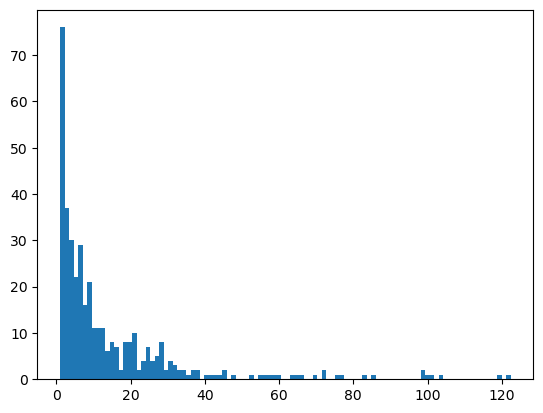

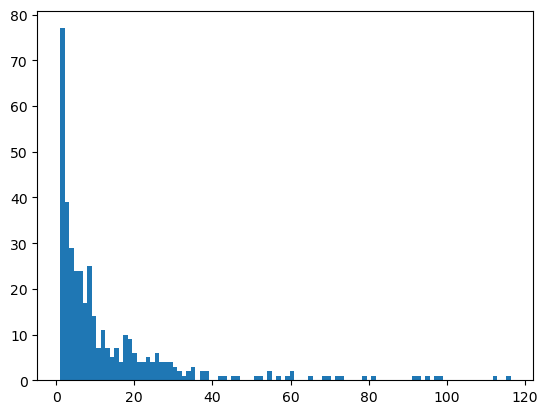

In [10]:
# Testando os cálculos de comprimento

skeleton_obj = Skeleton(esqueletos)

resumo = summarize(skeleton_obj)
display(resumo)

resumo_unique = resumo.drop_duplicates(subset='skeleton-id')
display(resumo_unique)

branch_distances = resumo_unique['branch-distance']
euclidean_distances = resumo_unique['euclidean-distance']

plt.plot()
plt.hist(branch_distances, bins=100)
plt.show()

plt.plot()
plt.hist(euclidean_distances, bins=100)
plt.show()

In [6]:
def reconstruir_3d_direto(img_3d_seg_2d, eixo):

    if eixo not in ['x', 'y', 'z']:
        raise ValueError("Eixo deve ser 'x', 'y' ou 'z'.")

    img_3d_labeled = np.zeros_like(img_3d_seg_2d)

    if eixo == 'x':
        num_layers = img_3d_seg_2d.shape[0]
        img_3d_labeled[0,:,:] = img_3d_seg_2d[0, :, :]
    if eixo == 'y':
        num_layers = img_3d_seg_2d.shape[1]
        img_3d_labeled[:,0,:] = img_3d_seg_2d[:, 0, :]
    if eixo == 'z':
        num_layers = img_3d_seg_2d.shape[2]
        img_3d_labeled[:,:,0] = img_3d_seg_2d[:, :, 0]
    

    for layer in range(1, num_layers-1):
        if eixo == 'x':
            # Seleciona 2 camadas subsequentes
            current_layer = img_3d_seg_2d[layer, :, :]
            lower_layer = img_3d_seg_2d[layer-1, :, :]

            # Verifica as labels da camada inferior
            lower_labels = np.unique(lower_layer)
            lower_labels = lower_labels[lower_labels != 0] # Ignora o background

            for lbl in lower_labels:
                # Faz uma máscara da label inferior para comparar com as mesmas posições da camada superior
                label_mask = (lower_layer == lbl)

                overlaped_labels = np.unique(np.where(label_mask, current_layer, 0))
                overlaped_labels = overlaped_labels[overlaped_labels != 0]

                # current_layer[np.isin(current_layer, overlaped_labels)] = lbl
                # current_layer[(label_mask) & (current_layer != 0)] = lbl
                if len(overlaped_labels) > 0:
                    current_layer[current_layer == overlaped_labels[0]] = lbl

                img_3d_labeled[layer, :, :] = current_layer
        
        if eixo == 'z':
            # Seleciona 2 camadas subsequentes
            current_layer = img_3d_seg_2d[:, :, layer]
            lower_layer = img_3d_seg_2d[:, :, layer-1]

            # Verifica as labels da camada inferior
            lower_labels = np.unique(lower_layer)
            lower_labels = lower_labels[lower_labels != 0] # Ignora o background

            for lbl in lower_labels:
                # Faz uma máscara da label inferior para comparar com as mesmas posições da camada superior
                label_mask = (lower_layer == lbl)

                overlaped_labels = np.unique(np.where(label_mask, current_layer, 0))
                overlaped_labels = overlaped_labels[overlaped_labels != 0]

                # current_layer[np.isin(current_layer, overlaped_labels)] = lbl
                # current_layer[(label_mask) & (current_layer != 0)] = lbl
                if len(overlaped_labels) > 0:
                    current_layer[current_layer == overlaped_labels[0]] = lbl

                img_3d_labeled[:, :, layer] = current_layer
    
    return img_3d_labeled

def reconstruir_3d_area(img_3d_seg_2d, eixo):

    if eixo not in ['x', 'y', 'z']:
        raise ValueError("Eixo deve ser 'x', 'y' ou 'z'.")

    img_3d_labeled = np.zeros_like(img_3d_seg_2d)

    if eixo == 'x':
        num_layers = img_3d_seg_2d.shape[0]
        img_3d_labeled[0,:,:] = img_3d_seg_2d[0, :, :]
    if eixo == 'y':
        num_layers = img_3d_seg_2d.shape[1]
        img_3d_labeled[:,0,:] = img_3d_seg_2d[:, 0, :]
    if eixo == 'z':
        num_layers = img_3d_seg_2d.shape[2]
        img_3d_labeled[:,:,0] = img_3d_seg_2d[:, :, 0]

    for layer in range(1, num_layers-1):
        if eixo == 'x':
            # Seleciona 2 camadas subsequentes
            current_layer = img_3d_seg_2d[layer, :, :]
            lower_layer = img_3d_seg_2d[layer-1, :, :]

            # Verifica as labels da camada superior
            current_labels = np.unique(current_layer)
            current_labels = current_labels[current_labels != 0] # Ignora o background

            for lbl in current_labels:
                # Faz uma máscara da label superior para comparar com as mesmas posições da camada superior
                label_mask = (current_layer == lbl)

                lower_mask = np.where(label_mask, lower_layer, 0)
                overlaped_labels = np.unique(lower_mask)
                overlaped_labels = overlaped_labels[overlaped_labels != 0]

                if len(overlaped_labels) > 0:
                    if len(overlaped_labels) > 1:
                        lbl_area = []
                        for lower_lbl in overlaped_labels:
                            n_pixels = np.sum(lower_mask == lower_lbl)
                            lbl_area = np.append(lbl_area, n_pixels)
                        maior_area = np.argmax(lbl_area)
                        current_layer[label_mask] = overlaped_labels[maior_area]
                    else:
                        current_layer[label_mask] = overlaped_labels[0]

                img_3d_labeled[layer, :, :] = current_layer
        
        if eixo == 'z':
            # Seleciona 2 camadas subsequentes
            current_layer = img_3d_seg_2d[:, :, layer]
            lower_layer = img_3d_seg_2d[:, :, layer-1]

            # Verifica as labels da camada superior
            current_labels = np.unique(current_layer)
            current_labels = current_labels[current_labels != 0] # Ignora o background

            for lbl in current_labels:
                # Faz uma máscara da label superior para comparar com as mesmas posições da camada superior
                label_mask = (current_layer == lbl)

                lower_mask = np.where(label_mask, lower_layer, 0)
                overlaped_labels = np.unique(lower_mask)
                overlaped_labels = overlaped_labels[overlaped_labels != 0]

                if len(overlaped_labels) > 0:
                    if len(overlaped_labels) > 1:
                        lbl_area = []
                        for lower_lbl in overlaped_labels:
                            n_pixels = np.sum(lower_mask == lower_lbl)
                            lbl_area = np.append(lbl_area, n_pixels)
                        maior_area = np.argmax(lbl_area)
                        current_layer[label_mask] = overlaped_labels[maior_area]
                    else:
                        current_layer[label_mask] = overlaped_labels[0]

                img_3d_labeled[:, :, layer] = current_layer
    
    return img_3d_labeled

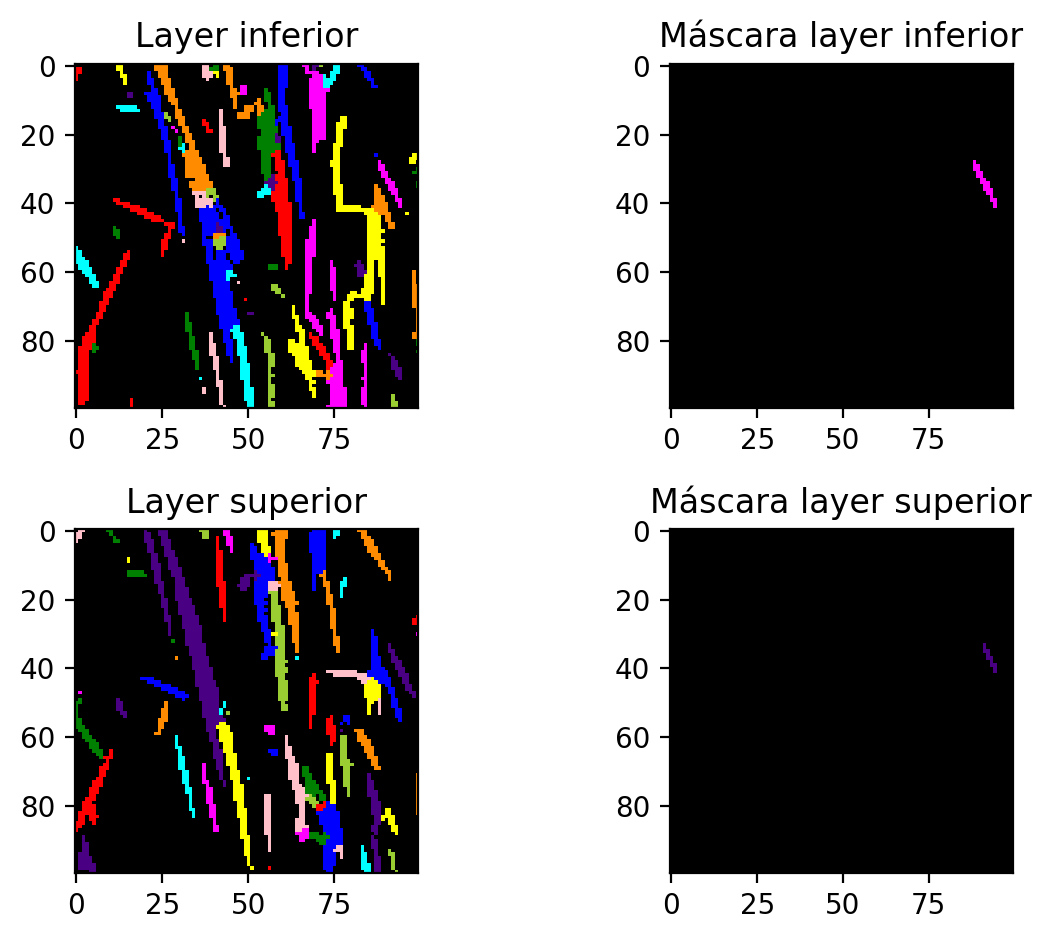

Label selecionada da camada inferior:  7
Labels exatamente acima na camada superior:  [244]
Labels exatamente acima na camada superior pós propragaçaõ:  [7]


In [12]:
tiff_test = fibras_separadas[100:200, 100:200, 200:205].copy()

current_layer = tiff_test[:, :, 1]
lower_layer = tiff_test[:, :, 1-1]

####### Para visualização, apenas #########

current_layer_rgb = label2rgb(current_layer, bg_label=0)
lower_layer_rgb = label2rgb(lower_layer, bg_label=0)

###########################################

test_label = 3

lower_labels = np.unique(lower_layer)
lower_labels = lower_labels[lower_labels != 0] # Ignora o background

label_mask = (lower_layer == lower_labels[test_label])

####### Para visualização, apenas #########

lower_layer_masked = np.zeros_like(lower_layer_rgb)
current_layer_masked = np.zeros_like(current_layer_rgb)

lower_layer_masked[label_mask] = lower_layer_rgb[label_mask]

current_layer_masked[label_mask] = current_layer_rgb[label_mask]

# lower_layer_masked = np.where(label_mask, lower_layer, 0)

# current_layer_masked = np.where(label_mask, current_layer, 0)

###########################################

plt.figure(dpi=200)

plt.subplot(2,2,1)
plt.imshow(label2rgb(lower_layer, bg_label=0), cmap='gray')
plt.title("Layer inferior")

plt.subplot(2,2,2)
plt.imshow(lower_layer_masked, cmap='gray')
plt.title("Máscara layer inferior")

overlaped_labels = np.unique(np.where(label_mask, current_layer, 0))
overlaped_labels = overlaped_labels[overlaped_labels != 0]

plt.subplot(2,2,3)
plt.imshow(label2rgb(current_layer, bg_label=0), cmap='gray')
plt.title("Layer superior")

plt.subplot(2,2,4)
plt.imshow(current_layer_masked, cmap='gray')
plt.title("Máscara layer superior")

plt.tight_layout()
plt.show()

current_layer[np.isin(current_layer, overlaped_labels)] = lower_labels[test_label]

####### Para visualização, apenas #########

# current_layer_rgb[label_mask] = lower_layer_rgb[label_mask]

# current_layer_rgb = label2rgb(current_layer, bg_label=0)
# current_layer_masked[label_mask] = current_layer_rgb[label_mask]


###########################################

# plt.subplot(3,2,5)
# plt.imshow(current_layer_masked, cmap='gray')
# plt.title("Propagação")

# plt.subplot(3,2,6)
# plt.imshow(label2rgb(current_layer, bg_label=0), cmap='gray')
# plt.title("Camada atual atualizada")

# plt.tight_layout()
# plt.show()

print('Label selecionada da camada inferior: ', lower_labels[test_label])

print('Labels exatamente acima na camada superior: ', overlaped_labels)

current_layer_masked = np.where(label_mask, current_layer, 0)

overlaped_labels = np.unique(current_layer_masked)
overlaped_labels = overlaped_labels[overlaped_labels != 0]

print('Labels exatamente acima na camada superior pós propragaçaõ: ', overlaped_labels)

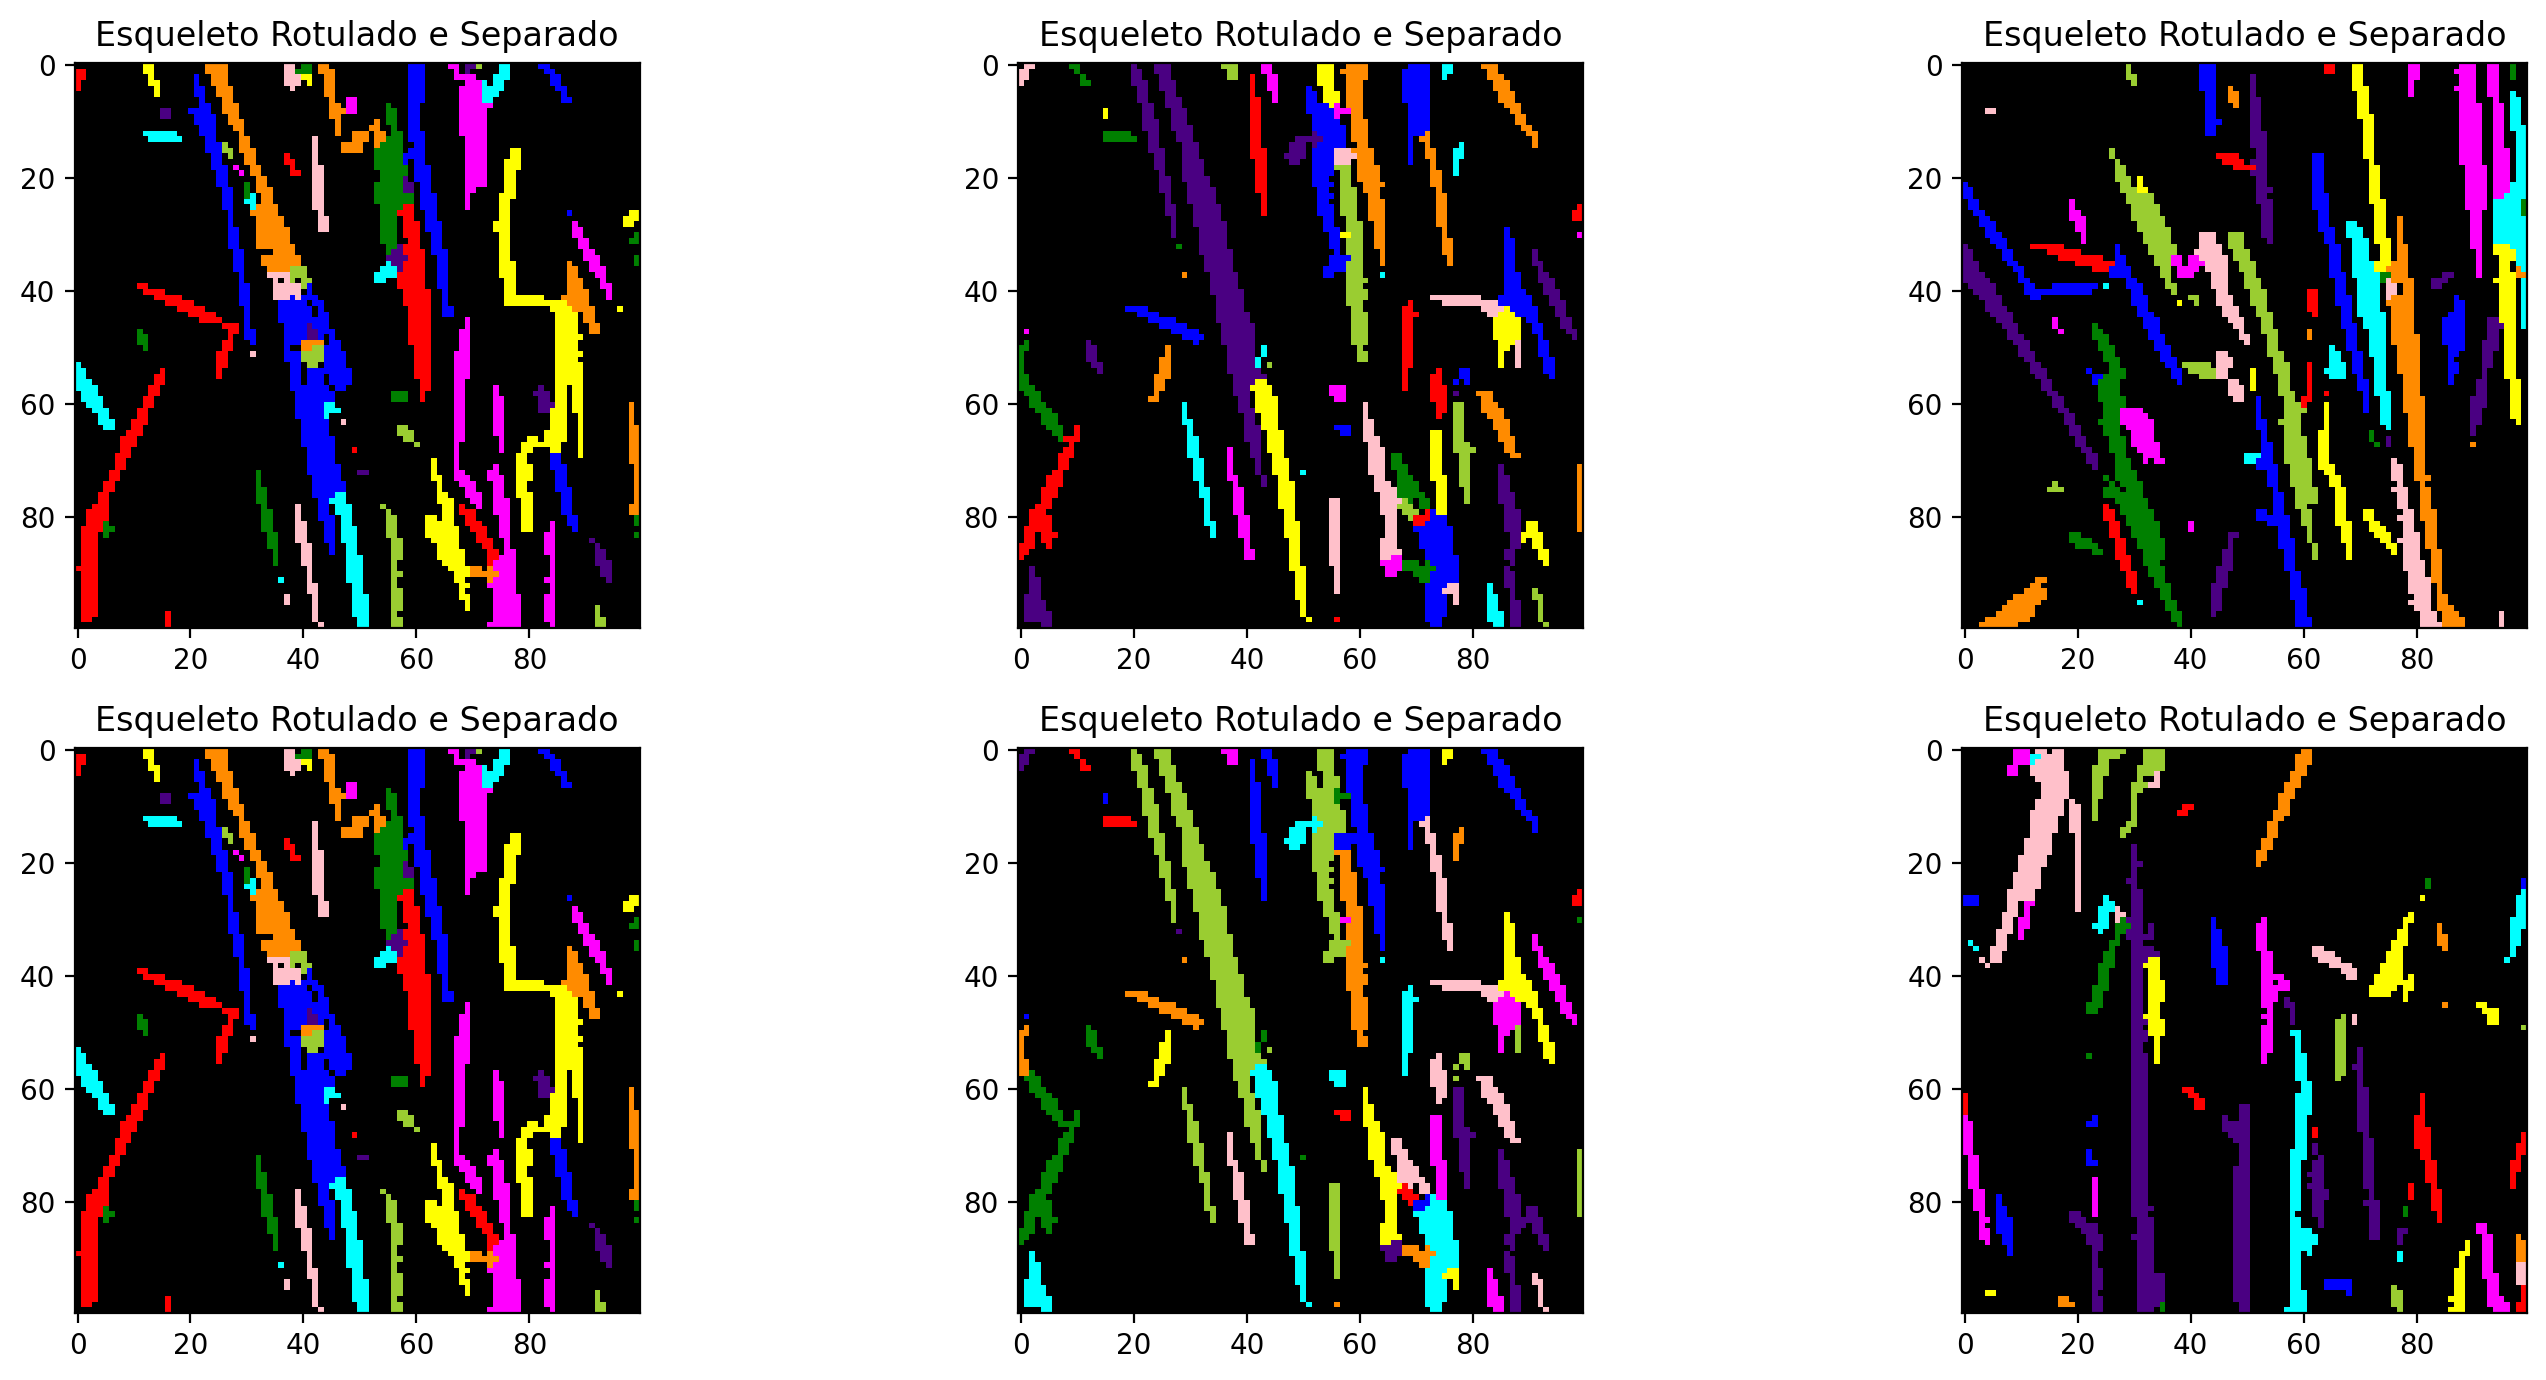

[  0   3   4   5   7  12  18  19  20  22  23  26  27  31  33  35  36  39
  45  46  47  52  53  56  57  59  60  65  66  68  73  80  84  86  88  89
  90  93  96 100 101 102 104 105 107 109 113 118 123 127 128 129 162 175
 179 182 197 200 201 203 204 206 207 208 218 219 222 226 227 229 231 234
 235 236 243 247 248 254 255]
[  0   5   9  16  31  35  42  45  59  60  65  73  77  86  88  90  94  95
  96 100 101 102 104 105 107 109 113 114 118 128 155 170 200 201 203 205
 206 207 217 218 226 227 235 236 238 239 242 248 249 252 255]


In [13]:
# Primeiro teste: 6 layers do centro do material

tiff_test = fibras_separadas[100:200, 100:200, 200:250].copy()

plt.figure(figsize=(15, 7), dpi=200)

plt.subplot(2, 3, 1)
plt.imshow(label2rgb(tiff_test[:, :, 0], bg_label=0), cmap='gray')
plt.title("Esqueleto Rotulado e Separado")
# plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(label2rgb(tiff_test[:, :, 1], bg_label=0), cmap='gray')
plt.title("Esqueleto Rotulado e Separado")
# plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(label2rgb(tiff_test[:, :, 15], bg_label=0), cmap='gray')
plt.title("Esqueleto Rotulado e Separado")
# plt.axis('off')

res = reconstruir_3d_direto(tiff_test, eixo)

plt.subplot(2, 3, 4)
plt.imshow(label2rgb(res[:,:,0], bg_label=0), cmap='gray')
plt.title("Esqueleto Rotulado e Separado")
# plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(label2rgb(res[:,:,1], bg_label=0), cmap='gray')
plt.title("Esqueleto Rotulado e Separado")
# plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(label2rgb(res[:,:,48], bg_label=0), cmap='gray')
plt.title("Esqueleto Rotulado e Separado")
# plt.axis('off')

plt.tight_layout()
plt.show()

print(np.unique(res[:,:,0]))
print(np.unique(res[:,:,1]))

In [ ]:
# salvando a imagem resultante da composição

# tifffile.imwrite("./data/2d-res/composed_area_x.tif", res[:30,:30,:])
# scp homero_castro@litc59:/home/homero_castro/toronto/data/2d-res/composed_area_x.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\data\2d-res
# napari ./data/2d-res/composed_area_x.tif --layer-type labels

# tifffile.imwrite("./data/2d-res/composed_area_z.tif", res[:30,:30,:])
# scp homero_castro@litc59:/home/homero_castro/toronto/data/2d-res/composed_area_z.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\data\2d-res
# napari ./data/2d-res/composed_area_z.tif --layer-type labels

# tifffile.imwrite("./data/2d-res/composed_direct_x.tif", res[:30,:30,:])
# scp homero_castro@litc59:/home/homero_castro/toronto/data/2d-res/composed_direct_x.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\data\2d-res
# napari ./data/2d-res/composed_direct_x.tif --layer-type labels

# tifffile.imwrite("./data/2d-res/composed_direct_z.tif", res[:30,:30,:])
# scp homero_castro@litc59:/home/homero_castro/toronto/data/2d-res/composed_direct_z.tif C:\Users\Homero\documents\LITC\Toronto_Fibers\data\2d-res
# napari ./data/2d-res/composed_direct_z.tif --layer-type labels

In [7]:
def calcula_comp_2d(esqueleto_separado_3d, eixo):
    if eixo not in ['x', 'y', 'z']:
        raise ValueError("Eixo deve ser 'x', 'y' ou 'z'.")
    
    if eixo == 'z':
        # Número de layers no eixo
        n_layers = esqueleto_separado_3d.shape[2]

        # Arrays de distância e # de pixels como métricas de comprimento
        euclid_dist = np.array([])
        branch_n_pixels = np.array([])

        longest = 0

        # Itera em cada layer e atualiza os valores dos arrays
        for layer in range(n_layers):
            current_layer = esqueleto_separado_3d[:,:,layer]
            skeleton_obj = Skeleton(current_layer)
            resume = summarize(skeleton_obj, separator='-')
            resume.drop_duplicates(subset='skeleton-id')
            euclid_dist = np.append(euclid_dist, resume['euclidean-distance'])
            branch_n_pixels = np.append(branch_n_pixels, resume['branch-distance'])
            if np.max(resume['euclidean-distance']) > longest:
                longest = np.max(resume['euclidean-distance'])
                longest_fiber_layer = layer
        print(f'THE LAYER: {longest_fiber_layer}!!')
        return euclid_dist, branch_n_pixels


THE LAYER: 217!!


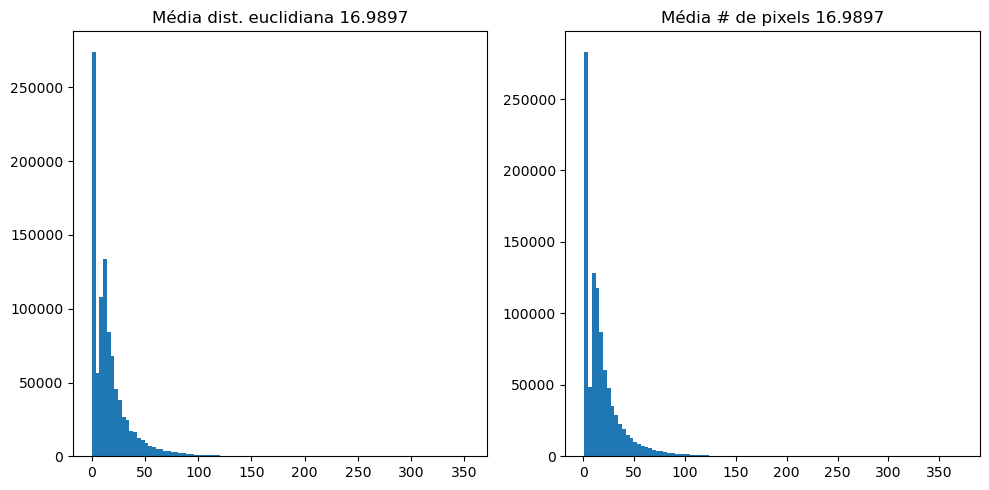

In [ ]:
skeleton_test = esqueletos_separados[:, 128:900, 132:535].copy()

euclid_dist, branch_n_pixels = calcula_comp_2d(skeleton_test, 'z')

plt.figure(figsize=(10, 5))

plt.subplot(1,2,1)
plt.hist(euclid_dist, bins=100)
plt.title(f'Média dist. euclidiana {np.mean(euclid_dist):.4f}')

plt.subplot(1,2,2)
plt.hist(branch_n_pixels, bins=100)
plt.title(f'Média # de pixels {np.mean(branch_n_pixels):.4f}')

plt.tight_layout()
plt.show()

In [1]:
plt.figure(dpi=300)
plt.imshow(fibras_separadas[:,:,132+217])

NameError: name 'plt' is not defined

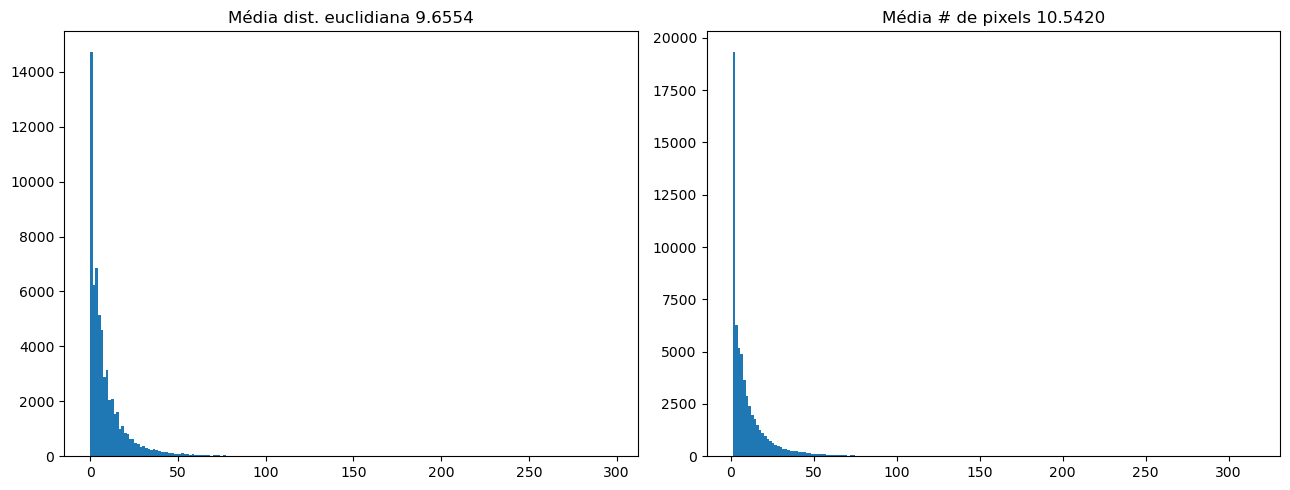

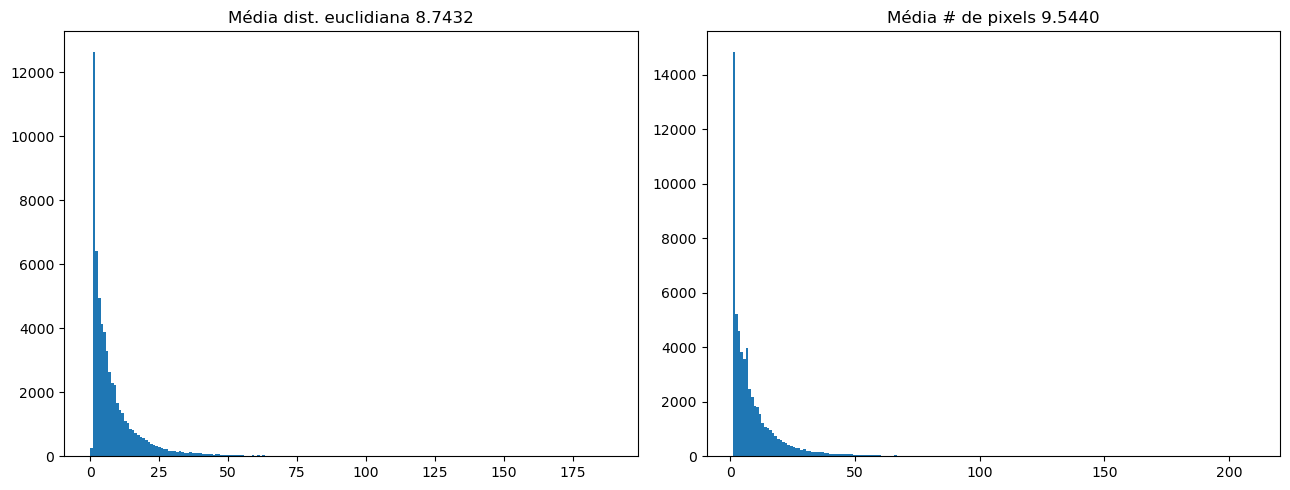

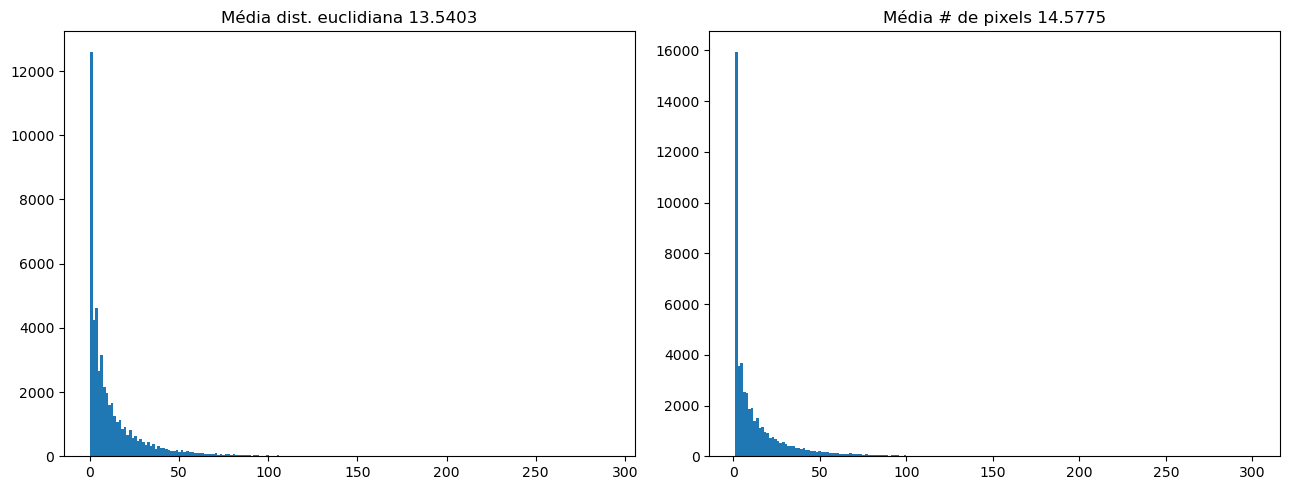

In [17]:
euclid_dist, branch_n_pixels = calcula_comp_2d(skeleton_test[:,:,:100], 'z')

plt.figure(figsize=(13, 5))

plt.subplot(1,2,1)
plt.hist(euclid_dist, bins=200)
plt.title(f'Média dist. euclidiana {np.mean(euclid_dist):.4f}')

plt.subplot(1,2,2)
plt.hist(branch_n_pixels, bins=200)
plt.title(f'Média # de pixels {np.mean(branch_n_pixels):.4f}')

plt.tight_layout()
plt.show()

euclid_dist, branch_n_pixels = calcula_comp_2d(skeleton_test[:,:,100:200], 'z')

plt.figure(figsize=(13, 5))

plt.subplot(1,2,1)
plt.hist(euclid_dist, bins=200)
plt.title(f'Média dist. euclidiana {np.mean(euclid_dist):.4f}')

plt.subplot(1,2,2)
plt.hist(branch_n_pixels, bins=200)
plt.title(f'Média # de pixels {np.mean(branch_n_pixels):.4f}')

plt.tight_layout()
plt.show()

euclid_dist, branch_n_pixels = calcula_comp_2d(skeleton_test[:,:,200:], 'z')

plt.figure(figsize=(13, 5))

plt.subplot(1,2,1)
plt.hist(euclid_dist, bins=200)
plt.title(f'Média dist. euclidiana {np.mean(euclid_dist):.4f}')

plt.subplot(1,2,2)
plt.hist(branch_n_pixels, bins=200)
plt.title(f'Média # de pixels {np.mean(branch_n_pixels):.4f}')

plt.tight_layout()
plt.show()

In [8]:
# Filtrar outliers via IQR e reprojetar histogramas (tratados)
def iqr_filter(arr, k=1.5):
    arr = np.asarray(arr)
    q1 = np.percentile(arr, 25)
    q3 = np.percentile(arr, 75)
    iqr = q3 - q1
    low = q1 - k * iqr
    high = q3 + k * iqr
    return arr[(arr >= low) & (arr <= high)], (q1, q3, low, high)

def plot_hist_filtered(euclid, branch, titulo_suffix="", bins=200, save_path=None):
    euclid_filt, stats_e = iqr_filter(euclid)
    branch_filt, stats_b = iqr_filter(branch)

    plt.figure(figsize=(13,5))
    plt.subplot(1,2,1)
    plt.hist(euclid_filt, bins=bins, color='steelblue', alpha=0.85)
    plt.title(f'Euclidean Distance (IQR) {titulo_suffix}\nN={len(euclid_filt)}  Mean={euclid_filt.mean():.3f}')
    plt.subplot(1,2,2)
    plt.hist(branch_filt, bins=bins, color='darkorange', alpha=0.85)
    plt.title(f'# Pixels (IQR) {titulo_suffix}\nN={len(branch_filt)}  Mean={branch_filt.mean():.3f}')
    plt.gcf().axes[0].axvline(euclid_filt.mean(), color='red', linestyle='--', linewidth=1)
    plt.gcf().axes[1].axvline(branch_filt.mean(), color='red', linestyle='--', linewidth=1)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()
    
    print(f"{titulo_suffix} Euclidean Distance -> Q1={stats_e[0]:.3f} Q3={stats_e[1]:.3f} Limits=({max(stats_e[2], 0):.3f}, {stats_e[3]:.3f})")
    print(f"{titulo_suffix} #Pixels            -> Q1={stats_b[0]:.3f} Q3={stats_b[1]:.3f} Limits=({max(stats_b[2], 0):.3f}, {stats_b[3]:.3f})")
    print()

In [ ]:

# Conjunto completo
euclid_full, branch_full = calcula_comp_2d(skeleton_test, 'z')
plot_hist_filtered(euclid_full, branch_full, "Full", bins=150)

# Primeiro terço (0:100)
euclid_a, branch_a = calcula_comp_2d(skeleton_test[:, :, :100], 'z')
plot_hist_filtered(euclid_a, branch_a, "Slices 0-99", bins=120)

# Segundo terço (100:200)
euclid_b, branch_b = calcula_comp_2d(skeleton_test[:, :, 100:200], 'z')
plot_hist_filtered(euclid_b, branch_b, "Slices 100-199", bins=120)

# Último terço (200:final)
euclid_c, branch_c = calcula_comp_2d(skeleton_test[:, :, 200:], 'z')
plot_hist_filtered(euclid_c, branch_c, "Slices 200-end", bins=120)

### Cálculo de tamanho das fibras para a imagem toda\n,

Para PPGFHNT0-1.0.tif:
- Eixo X:
    - Primeira layer completa: 0
    - Última layer completa: 1648
- Eixo Y:
    - Primeira layer completa: 128
    - Última layer completa: 900
- Eixo Z:
    - Primeira layer completa: 132
    - Última layer completa: 535

In [9]:
# Testando método de separação no bloco selecionado
binary_img = tiff_img > 113

eixo = 'z'

if eixo == 'x':
    for each_slice in tqdm(range(chosen_binary.shape[0]), desc="Processando slices ao longo do eixo X"):
        chosen_slice = chosen_binary[each_slice, :, :]
        # print(f"\nProcessando slice {each_slice+1}/{chosen_binary.shape[0]}...\n")
        fibras_separadas[each_slice, :, :], esqueletos_separados[each_slice, :, :] = separar_fibras(
            chosen_slice,
            angulo_limite_poda=45,
            remover_pequenos_esqueletos=False,
            tam_min_esqueleto=3,
            analise_local=True,
            range_local=20
        )
        # clear_output(wait=True)
elif eixo == 'y':
    for each_slice in tqdm(range(chosen_binary.shape[1]), desc="Processando slices ao longo do eixo Y"):
        chosen_slice = chosen_binary[:, each_slice, :]
        # print(f"\nProcessando slice {each_slice+1}/{chosen_binary.shape[1]}...\n")
        fibras_separadas[:, each_slice, :], esqueletos_separados[:, each_slice, :] = separar_fibras(
            chosen_slice,
            angulo_limite_poda=45,
            remover_pequenos_esqueletos=False,
            tam_min_esqueleto=3,
            analise_local=True,
            range_local=20
        )
        # clear_output(wait=True)
elif eixo == 'z':
    
    f_layers_sec = binary_img[:, 128:900, 132:535]

    fibras_separadas = np.zeros_like(f_layers_sec)
    esqueletos_separados = np.zeros_like(f_layers_sec)

    for each_slice in tqdm(range(f_layers_sec.shape[2]), desc="Processando slices ao longo do eixo Z"):
        chosen_slice = f_layers_sec[:, :, each_slice]
        # print(f"\nProcessando slice {each_slice+1}/{chosen_binary.shape[2]}...\n")
        fibras_separadas[:, :, each_slice], esqueletos_separados[:, :, each_slice] = separar_fibras(
            chosen_slice,
            angulo_limite_poda=45,
            remover_pequenos_esqueletos=False,
            tam_min_esqueleto=20,
            analise_local=True,
            range_local=20
        )
        # clear_output(wait=True)

Processando slices ao longo do eixo Z: 100%|██████████| 403/403 [33:55<00:00,  5.05s/it]


THE LAYER: 41!!
Histograma de tamanho das fibras considerando todas as layers:


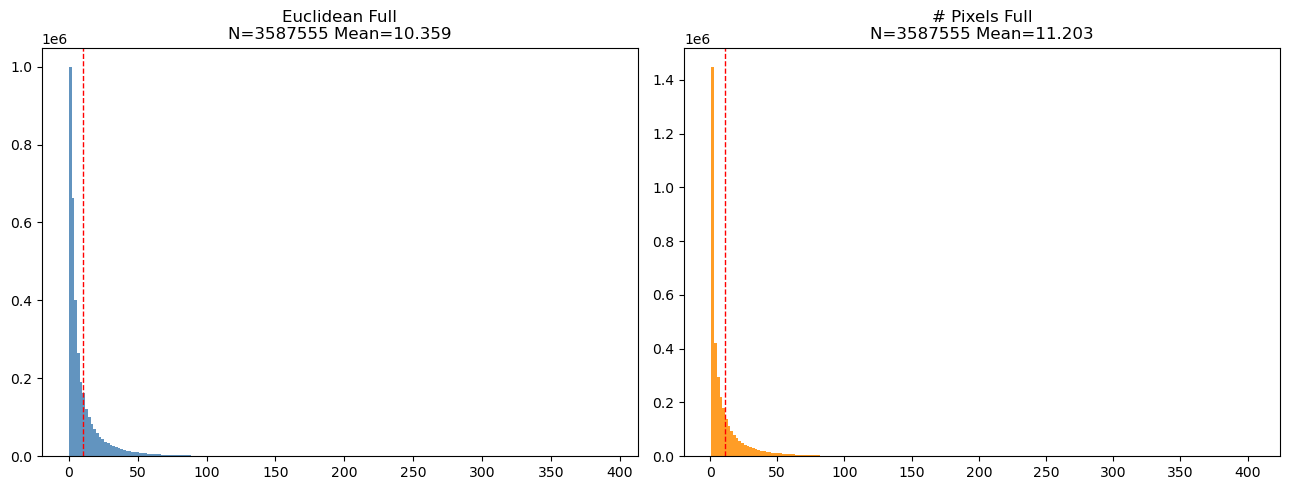

Histograma com IQR de tamanho das fibras considerando todas as layers:


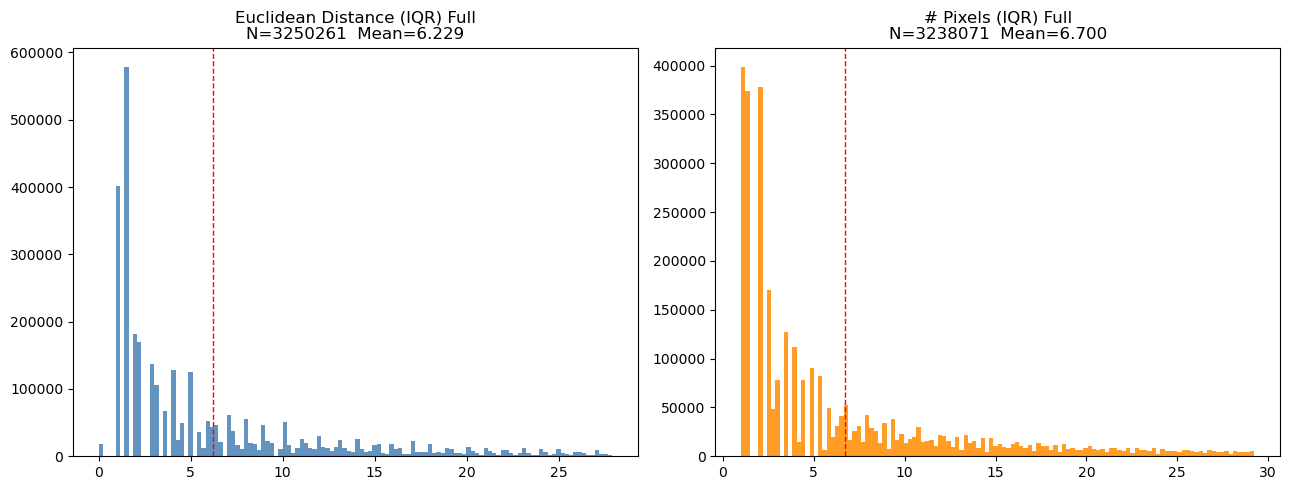

Full Euclidean Distance -> Q1=1.414 Q3=12.042 Limits=(0.000, 27.983)
Full #Pixels            -> Q1=2.000 Q3=12.899 Limits=(0.000, 29.249)

Histograma com IQR de tamanho das fibras considerando as 175 primeiras layers:
THE LAYER: 41!!


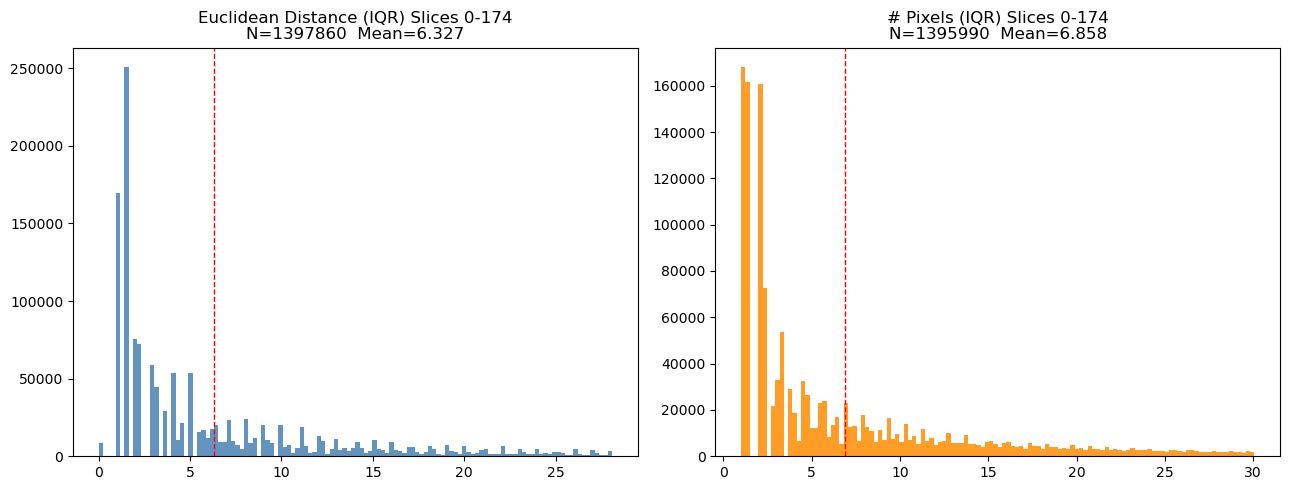

Slices 0-174 Euclidean Distance -> Q1=1.414 Q3=12.083 Limits=(0.000, 28.086)
Slices 0-174 #Pixels            -> Q1=2.000 Q3=13.243 Limits=(0.000, 30.107)

Histograma com IQR de tamanho das fibras considerando as 50 layers do centro:
THE LAYER: 29!!


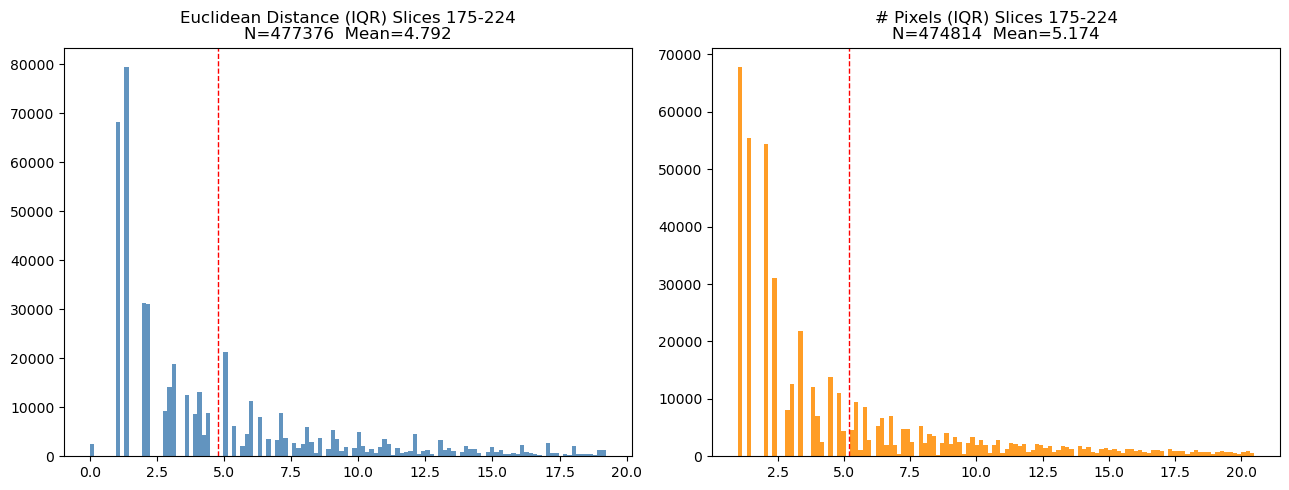

Slices 175-224 Euclidean Distance -> Q1=1.414 Q3=8.544 Limits=(0.000, 19.239)
Slices 175-224 #Pixels            -> Q1=2.000 Q3=9.414 Limits=(0.000, 20.536)

Histograma com IQR de tamanho das fibras considerando as 178 útimas layers:
THE LAYER: 124!!


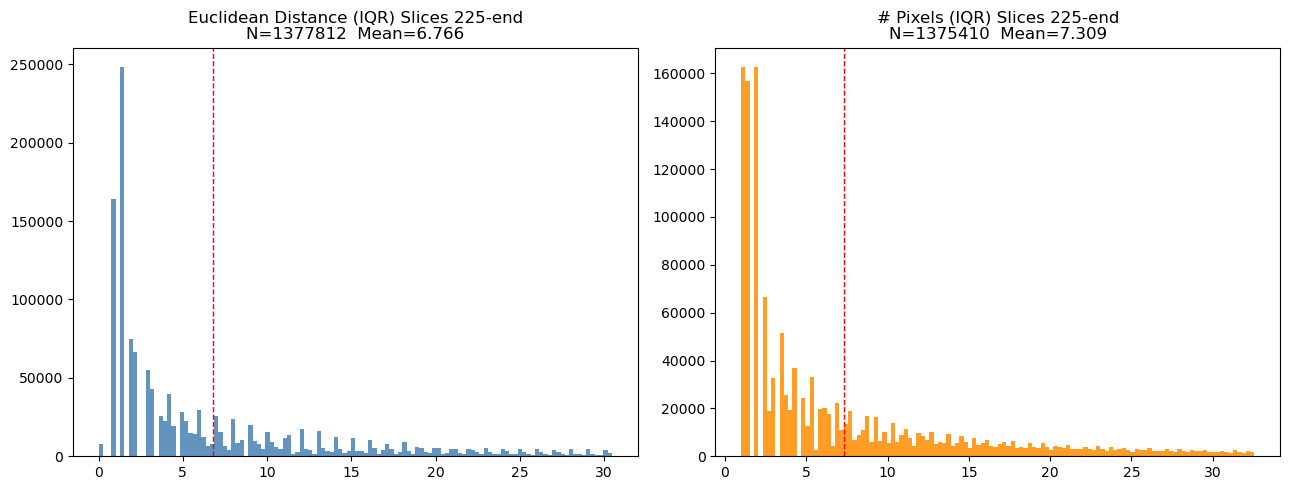

Slices 225-end Euclidean Distance -> Q1=1.414 Q3=13.038 Limits=(0.000, 30.475)
Slices 225-end #Pixels            -> Q1=2.000 Q3=14.243 Limits=(0.000, 32.607)



In [10]:
euclid_full, branch_full = calcula_comp_2d(esqueletos_separados, 'z')

os.makedirs("metric_plots", exist_ok=True)

print('Histograma de tamanho das fibras considerando todas as layers:')

plt.figure(figsize=(13, 5))

plt.subplot(1,2,1)
plt.hist(euclid_full, bins=200, color='steelblue', alpha=0.85)
plt.title(f'Euclidean Full\nN={len(euclid_full)} Mean={euclid_full.mean():.3f}')

plt.subplot(1,2,2)
plt.hist(branch_full, bins=200, color='darkorange', alpha=0.85)
plt.title(f'# Pixels Full\nN={len(branch_full)} Mean={branch_full.mean():.3f}')

plt.gcf().axes[0].axvline(euclid_full.mean(), color='red', linestyle='--', linewidth=1)
plt.gcf().axes[1].axvline(branch_full.mean(), color='red', linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig("metric_plots/hist_rmsmall_false_full_raw.png")
plt.show()

print('Histograma com IQR de tamanho das fibras considerando todas as layers:')

plot_hist_filtered(euclid_full, branch_full, "Full", bins=120, save_path="metric_plots/hist_rmsmall_false_full_iqr.png")

print('Histograma com IQR de tamanho das fibras considerando as 175 primeiras layers:')

euclid_a, branch_a = calcula_comp_2d(esqueletos_separados[:, :, :175], 'z')
plot_hist_filtered(euclid_a, branch_a, "Slices 0-174", bins=120, save_path="metric_plots/hist_rmsmall_false_1st3_iqr.png")

print('Histograma com IQR de tamanho das fibras considerando as 50 layers do centro:')

euclid_b, branch_b = calcula_comp_2d(esqueletos_separados[:, :, 175:225], 'z')
plot_hist_filtered(euclid_b, branch_b, "Slices 175-224", bins=120, save_path="metric_plots/hist_rmsmall_false_2nd3_iqr.png")

print('Histograma com IQR de tamanho das fibras considerando as 178 útimas layers:')

euclid_c, branch_c = calcula_comp_2d(esqueletos_separados[:, :, 225:], 'z')
plot_hist_filtered(euclid_c, branch_c, "Slices 225-end", bins=120, save_path="metric_plots/hist_rmsmall_false_3rd3_iqr.png")

# scp -r homero_castro@litc59:/home/homero_castro/toronto/metric_plots C:\Users\Homero\documents\LITC\Toronto_Fibers

In [11]:
# Testando método de separação no bloco selecionado
binary_img = tiff_img > 113

eixo = 'z'

if eixo == 'x':
    for each_slice in tqdm(range(chosen_binary.shape[0]), desc="Processando slices ao longo do eixo X"):
        chosen_slice = chosen_binary[each_slice, :, :]
        # print(f"\nProcessando slice {each_slice+1}/{chosen_binary.shape[0]}...\n")
        fibras_separadas[each_slice, :, :], esqueletos_separados[each_slice, :, :] = separar_fibras(
            chosen_slice,
            angulo_limite_poda=45,
            remover_pequenos_esqueletos=False,
            tam_min_esqueleto=3,
            analise_local=True,
            range_local=20
        )
        # clear_output(wait=True)
elif eixo == 'y':
    for each_slice in tqdm(range(chosen_binary.shape[1]), desc="Processando slices ao longo do eixo Y"):
        chosen_slice = chosen_binary[:, each_slice, :]
        # print(f"\nProcessando slice {each_slice+1}/{chosen_binary.shape[1]}...\n")
        fibras_separadas[:, each_slice, :], esqueletos_separados[:, each_slice, :] = separar_fibras(
            chosen_slice,
            angulo_limite_poda=45,
            remover_pequenos_esqueletos=False,
            tam_min_esqueleto=3,
            analise_local=True,
            range_local=20
        )
        # clear_output(wait=True)
elif eixo == 'z':
    
    f_layers_sec = binary_img[:, 128:900, 132:535]

    fibras_separadas = np.zeros_like(f_layers_sec)
    esqueletos_separados = np.zeros_like(f_layers_sec)

    for each_slice in tqdm(range(f_layers_sec.shape[2]), desc="Processando slices ao longo do eixo Z"):
        chosen_slice = f_layers_sec[:, :, each_slice]
        # print(f"\nProcessando slice {each_slice+1}/{chosen_binary.shape[2]}...\n")
        fibras_separadas[:, :, each_slice], esqueletos_separados[:, :, each_slice] = separar_fibras(
            chosen_slice,
            angulo_limite_poda=45,
            remover_pequenos_esqueletos=True,
            tam_min_esqueleto=10,
            analise_local=True,
            range_local=20
        )
        # clear_output(wait=True)

Processando slices ao longo do eixo Z: 100%|██████████| 403/403 [33:01<00:00,  4.92s/it]


THE LAYER: 41!!
Histograma de tamanho das fibras considerando todas as layers:


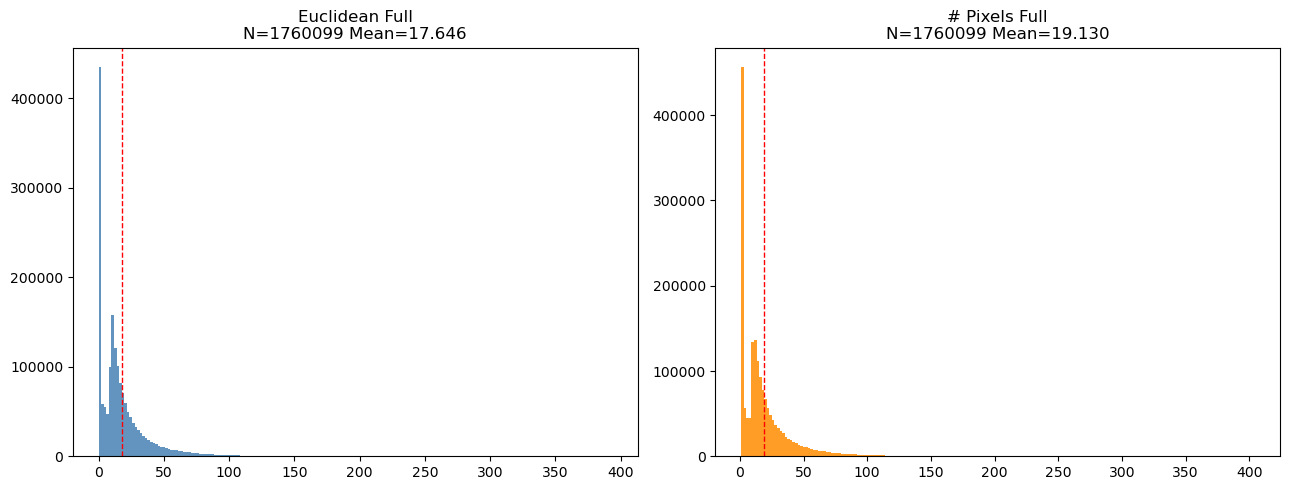

Histograma com IQR de tamanho das fibras considerando todas as layers:


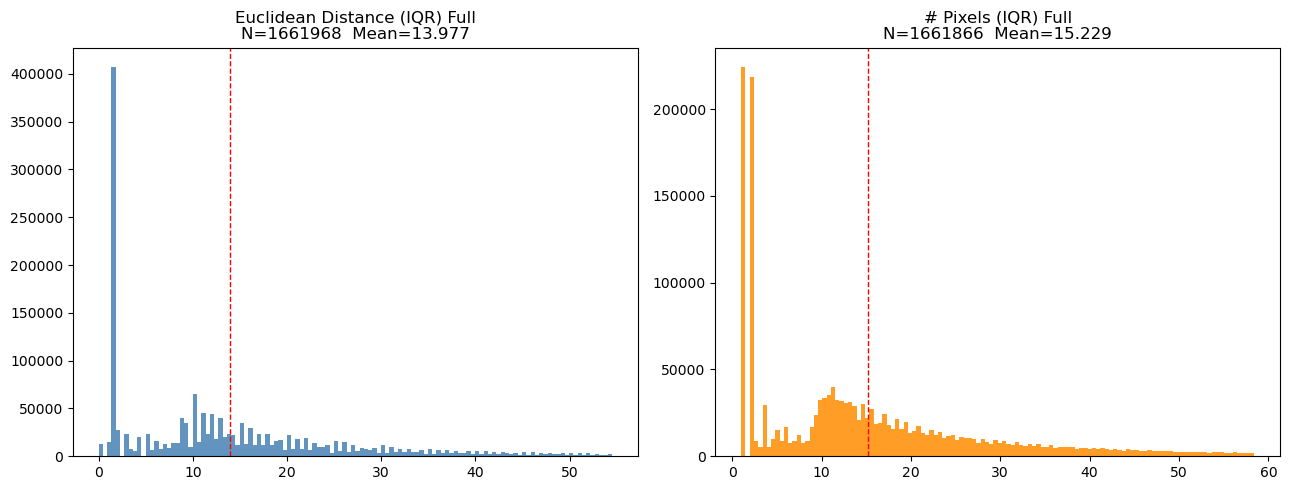

Full Euclidean Distance -> Q1=2.000 Q3=23.022 Limits=(0.000, 54.554)
Full #Pixels            -> Q1=2.414 Q3=24.828 Limits=(0.000, 58.450)

Histograma com IQR de tamanho das fibras considerando as 175 primeiras layers:
THE LAYER: 41!!


<Figure size 640x480 with 0 Axes>

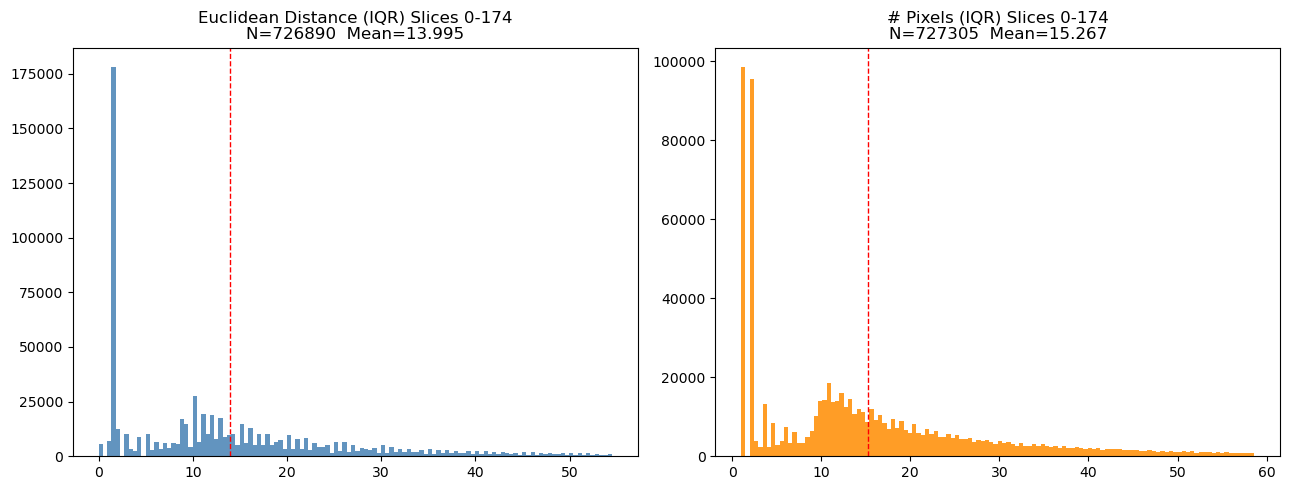

Slices 0-174 Euclidean Distance -> Q1=2.000 Q3=23.022 Limits=(0.000, 54.554)
Slices 0-174 #Pixels            -> Q1=2.414 Q3=24.899 Limits=(0.000, 58.627)

Histograma com IQR de tamanho das fibras considerando as 50 layers do centro:
THE LAYER: 29!!


<Figure size 640x480 with 0 Axes>

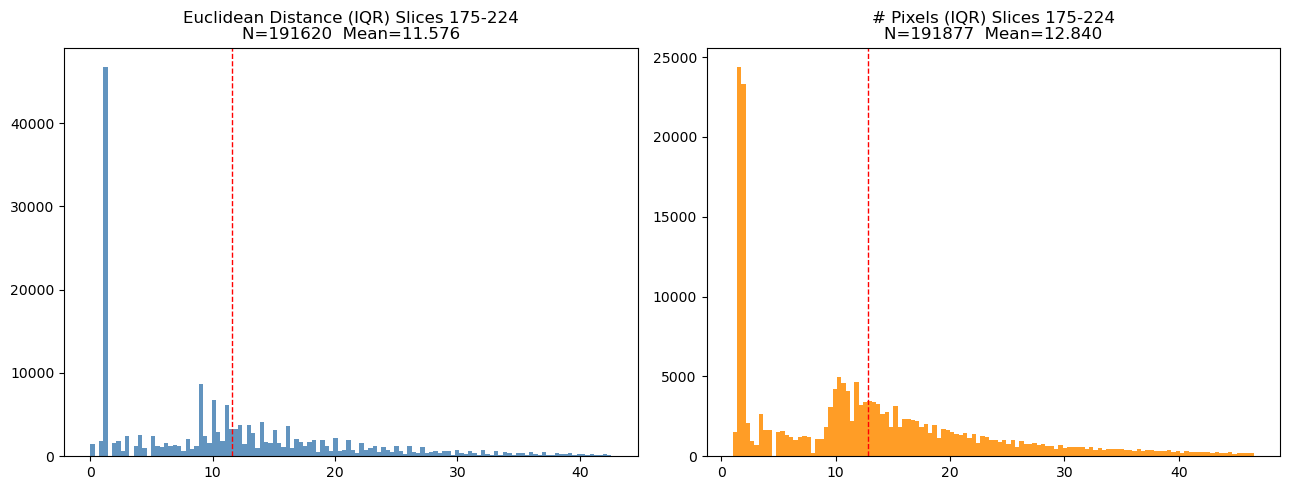

Slices 175-224 Euclidean Distance -> Q1=2.000 Q3=18.248 Limits=(0.000, 42.621)
Slices 175-224 #Pixels            -> Q1=2.414 Q3=20.071 Limits=(0.000, 46.556)

Histograma com IQR de tamanho das fibras considerando as 178 útimas layers:
THE LAYER: 124!!


<Figure size 640x480 with 0 Axes>

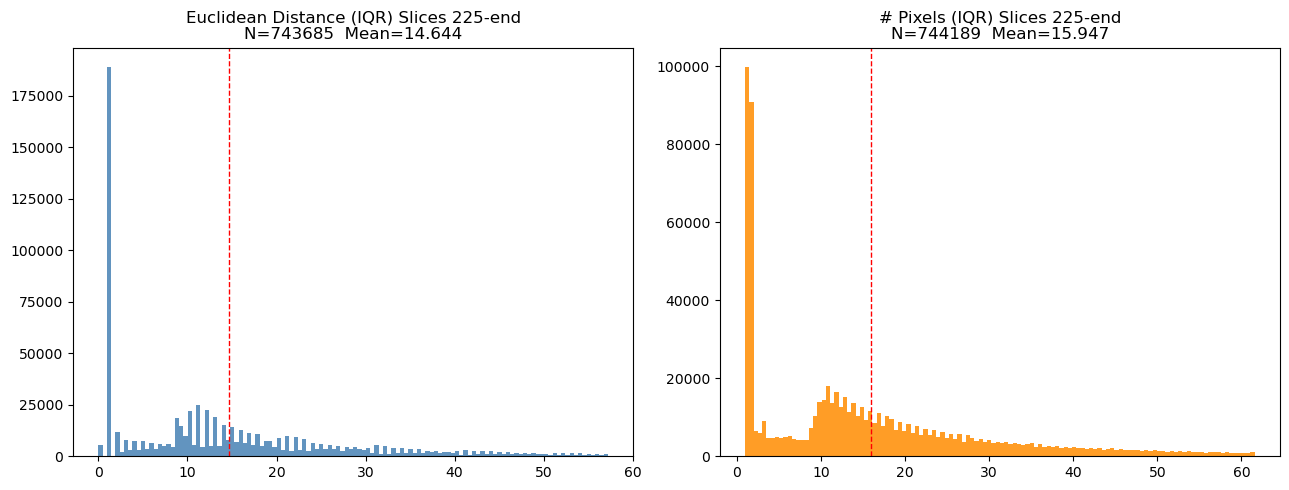

Slices 225-end Euclidean Distance -> Q1=2.000 Q3=24.083 Limits=(0.000, 57.208)
Slices 225-end #Pixels            -> Q1=2.414 Q3=26.071 Limits=(0.000, 61.556)



<Figure size 640x480 with 0 Axes>

In [12]:
euclid_full, branch_full = calcula_comp_2d(esqueletos_separados, 'z')

os.makedirs("metric_plots", exist_ok=True)

print('Histograma de tamanho das fibras considerando todas as layers:')

plt.figure(figsize=(13, 5))

plt.subplot(1,2,1)
plt.hist(euclid_full, bins=200, color='steelblue', alpha=0.85)
plt.title(f'Euclidean Full\nN={len(euclid_full)} Mean={euclid_full.mean():.3f}')

plt.subplot(1,2,2)
plt.hist(branch_full, bins=200, color='darkorange', alpha=0.85)
plt.title(f'# Pixels Full\nN={len(branch_full)} Mean={branch_full.mean():.3f}')

plt.gcf().axes[0].axvline(euclid_full.mean(), color='red', linestyle='--', linewidth=1)
plt.gcf().axes[1].axvline(branch_full.mean(), color='red', linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig("metric_plots/hist_rmsmall_true_full_raw.png")
plt.show()

print('Histograma com IQR de tamanho das fibras considerando todas as layers:')

plot_hist_filtered(euclid_full, branch_full, "Full", bins=120)
fig = plt.gcf()
fig.savefig("metric_plots/hist_rmsmall_true_full_iqr.png")

print('Histograma com IQR de tamanho das fibras considerando as 175 primeiras layers:')

euclid_a, branch_a = calcula_comp_2d(esqueletos_separados[:, :, :175], 'z')
plot_hist_filtered(euclid_a, branch_a, "Slices 0-174", bins=120)
fig = plt.gcf()
fig.savefig("metric_plots/hist_rmsmall_true_1st3_iqr.png")

print('Histograma com IQR de tamanho das fibras considerando as 50 layers do centro:')

euclid_b, branch_b = calcula_comp_2d(esqueletos_separados[:, :, 175:225], 'z')
plot_hist_filtered(euclid_b, branch_b, "Slices 175-224", bins=120)
fig = plt.gcf()
fig.savefig("metric_plots/hist_rmsmall_true_2nd3_iqr.png")

print('Histograma com IQR de tamanho das fibras considerando as 178 útimas layers:')

euclid_c, branch_c = calcula_comp_2d(esqueletos_separados[:, :, 225:], 'z')
plot_hist_filtered(euclid_c, branch_c, "Slices 225-end", bins=120)
fig = plt.gcf()
fig.savefig("metric_plots/hist_rmsmall_true_3rd3_iqr.png")

# scp -r homero_castro@litc59:/home/homero_castro/toronto/metric_plots C:\Users\Homero\documents\LITC\Toronto_Fibers